# Métodos del mapa de investigación

Monitoreo indirecto de puentes con smartphones (*drive-by*): explicación de los **métodos** que aparecen en el mapa de investigación. El notebook sigue el orden del mapa, pero solo contiene información de métodos; solo aparecen los encabezados que ya tienen algún método.

<a id="indice"></a>
## Índice

- [2 Modal identification](#modal-identification)
  - [2.1 Natural frequencies](#natural-frequencies)
    - [2.1.1 Signal decomposition](#natural-frequencies-signal-decomposition)
      - [2.1.1.1 Cross-correlation](#cross-correlation)
      - [2.1.1.2 FDD (Frequency Domain Decomposition)](#fdd)
  - [2.2 Mode shapes](#mode-shapes)
    - [2.2.2 Signal decomposition](#mode-shapes-signal-decomposition)
      - [2.2.2.1 EMD + Hilbert transform](#emd-hilbert)
      - [2.2.2.2 FDD (Frequency Domain Decomposition)](#fdd-mode-shapes)
      - [2.2.2.3 Wavelet transform (SSWT)](#wavelet-sswt)
    - [2.2.4 Build the shape along the bridge](#build-shape)
      - [2.2.4.1 SVD of the completed matrix](#svd-completed-matrix)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ssqueezepy import Wavelet, cwt, ssq_cwt
from ssqueezepy.experimental import scale_to_freq
from PyEMD import EMD
from scipy.interpolate import CubicSpline
from scipy.signal import argrelextrema, hilbert, csd

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


def morlet(t, w0=6.0):
    """Complex Morlet mother wavelet (Eq. 14): oscillation times a Gaussian bell."""
    return np.pi ** -0.25 * np.exp(1j * w0 * t) * np.exp(-t ** 2 / 2)


def scale_for_freq(f, w0=6.0):
    """Scale a whose wavelet oscillates at frequency f in Hz (Eq. 15 solved for a)."""
    return w0 / (2 * np.pi * f)


def scaled_wavelet(t, a, b, w0=6.0):
    """Mother wavelet stretched by scale a and shifted to time b (kernel of Eq. 16)."""
    return morlet((t - b) / a, w0) / np.sqrt(a)


def instantaneous_attributes(c, fs):
    """Envelope A(t) and instantaneous frequency f(t) in Hz of an IMF (Eqs. 12-13)."""
    z = hilbert(c)                      # analytic signal c + i H[c]
    amplitude = np.abs(z)
    phase = np.unwrap(np.angle(z))
    freq = np.gradient(phase) * fs / (2 * np.pi)
    return amplitude, freq


def cross_correlation(xi, xj, max_lag):
    """Biased estimate R_ij(k) = (1/N) sum_n x_i[n] x_j[n+k] for k = -max_lag..max_lag (Eq. 2)."""
    N = xi.size
    lags = np.arange(-max_lag, max_lag + 1)
    R = np.array([np.dot(xi[:N - k], xj[k:]) if k >= 0 else np.dot(xi[-k:], xj[:N + k])
                  for k in lags]) / N
    return lags, R


def modal_response(freqs, zeta, fs, n, rng):
    """Modal coordinates q_k(t), unit RMS: lightly damped modes driven by independent white noise."""
    w = 2 * np.pi * np.fft.rfftfreq(n, 1 / fs)
    q = []
    for fk in freqs:
        wk = 2 * np.pi * fk
        H = 1 / (wk ** 2 - w ** 2 + 2j * zeta * wk * w)          # FRF of one mode: narrow band around f_k
        qk = np.fft.irfft(np.fft.rfft(rng.standard_normal(n)) * H, n)
        q.append(qk / qk.std())
    return np.array(q)


def beam_modes(x_rel, n_modes):
    """Simply supported beam mode shapes sin(k pi x/L) at relative positions x/L (one column per mode)."""
    return np.column_stack([np.sin((k + 1) * np.pi * x_rel) for k in range(n_modes)])


def mac(a, b):
    """Modal Assurance Criterion: 1 = same shape up to a scale factor, 0 = unrelated."""
    return np.abs(np.vdot(a, b)) ** 2 / (np.vdot(a, a).real * np.vdot(b, b).real)


def real_shape(u, ref):
    """Rotate a complex singular vector to be real, scale it to max |value| = 1 and match the sign of ref."""
    u = u * np.exp(-1j * np.angle(u[np.argmax(np.abs(u))]))
    u = u.real / np.max(np.abs(u.real))
    return u if np.dot(u, ref) >= 0 else -u

---

<a id="modal-identification"></a>
## 2 Modal identification

---

<a id="natural-frequencies"></a>
### 2.1 Natural frequencies

<a id="natural-frequencies-signal-decomposition"></a>
#### 2.1.1 Signal decomposition

<a id="cross-correlation"></a>
##### 2.1.1.1 Cross-correlation

*No aparece en el mapa; se explica aquí porque es el primer paso del FDD.*

**Qué es**

- Mide qué tan parecidas son dos señales cuando una se desplaza en el tiempo respecto a la otra.
- Con una sola señal comparada consigo misma se llama **autocorrelación**.
- Su transformada de Fourier es la **densidad espectral cruzada** (CPSD, *cross power spectral density*): dice cuánta energía comparten las dos señales en cada frecuencia (teorema de Wiener–Khinchin).

**Para qué se aplica**

- Para encontrar el retraso entre dos señales y qué tanto se parecen.
- En análisis modal: para pasar de muchas señales medidas a una matriz que resume cómo se relacionan todos los puntos entre sí. En esa matriz el ruido aleatorio se promedia y quedan las vibraciones que los puntos comparten, que son los modos.

**Cómo funciona**

1. Se toman dos señales $x_i(t)$ y $x_j(t)$.
2. Se desplaza una un tiempo $\tau$, se multiplica punto por punto con la otra y se promedia.
3. Se repite para muchos $\tau$: sale una curva de correlación contra $\tau$. Si tiene un pico en $\tau=\tau_0$, las señales se parecen con un retraso $\tau_0$.
4. Con $n$ puntos de medición se calcula para todos los pares: sale una matriz $n\times n$ por cada $\tau$.
5. Cada señal de un puente es una combinación de los mismos modos con distintos pesos (la forma modal en ese punto). Por eso las señales de dos puntos son distintas, pero comparten las mismas coordenadas modales en el tiempo, y la correlación conserva esa estructura.

*Correlación cruzada (pasos 1–3).*

$$R_{ij}(\tau)=E\left[x_i(t)\,x_j(t+\tau)\right] \tag{1}$$

- $R_{ij}(\tau)$: correlación cruzada entre los puntos $i$ y $j$ para el desplazamiento $\tau$.
- $x_i(t)$, $x_j(t)$: señales en los puntos $i$ y $j$.
- $\tau$: desplazamiento en el tiempo, en s.
- $E[\cdot]$: promedio o valor esperado.

En palabras: se adelanta $x_j$ un tiempo $\tau$, se multiplica por $x_i$ y se promedia; si el resultado es grande, las dos señales se parecen con ese desplazamiento. Con $i=j$ es la autocorrelación.

*Estimación con señales muestreadas.*

$$\hat{R}_{ij}(k)=\frac{1}{N}\sum_{n=0}^{N-1-k}x_i[n]\,x_j[n+k] \tag{2}$$

- $\hat{R}_{ij}(k)$: estimación de la correlación para un desplazamiento de $k$ muestras ($\tau=k\,\Delta t$, con $\Delta t$ el paso de tiempo).
- $x_i[n]$, $x_j[n]$: muestra $n$ de cada señal.
- $N$: número de muestras.
- $k$: desplazamiento en muestras ($k\ge 0$; para $k<0$ se usa $\hat{R}_{ij}(-k)=\hat{R}_{ji}(k)$).

En palabras: es la Ec. 1 con una suma en lugar del valor esperado; para cada $k$ se suman los productos de las muestras que se traslapan y se divide entre $N$.

**Ejemplo sintético.** Dos señales iguales (ruido suavizado), la segunda atrasada 0.3 s.

Peak of the cross-correlation at tau = 0.30 s (true delay 0.3 s)


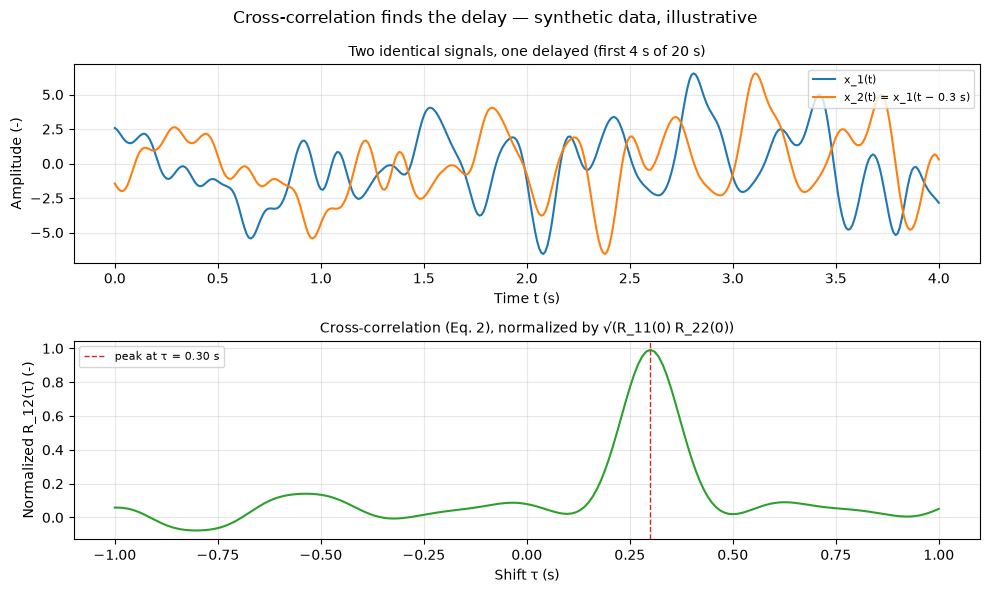

In [2]:
# Two identical signals, the second one delayed by 0.3 s, and their cross-correlation (illustrative)
rng_xc = np.random.default_rng(SEED)    # own generator: keeps the other sections unchanged
fs_c = 100.0                            # sampling rate, Hz
delay = 0.3                             # delay of x_2, s
n_c = int(20 * fs_c)                    # 20 s of signal
d = int(delay * fs_c)                   # delay in samples
kernel = np.exp(-0.5 * (np.arange(-15, 16) / 5) ** 2)              # Gaussian smoothing (about 0.05 s)
raw = np.convolve(rng_xc.standard_normal(n_c + d), kernel, mode="same")
x1_c = raw[d:]                          # x_1(t)
x2_c = raw[:n_c]                        # x_2(t) = x_1(t - 0.3 s)
t_c = np.arange(n_c) / fs_c

lags, R12 = cross_correlation(x1_c, x2_c, max_lag=int(1.0 * fs_c))   # Eq. 2
rho12 = R12 / np.sqrt(np.mean(x1_c ** 2) * np.mean(x2_c ** 2))       # normalized by R_11(0), R_22(0)
tau = lags / fs_c
tau_peak = tau[np.argmax(rho12)]
print(f"Peak of the cross-correlation at tau = {tau_peak:.2f} s (true delay {delay} s)")

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
show = t_c <= 4
axes[0].plot(t_c[show], x1_c[show], color="C0", label="x_1(t)")
axes[0].plot(t_c[show], x2_c[show], color="C1", label="x_2(t) = x_1(t − 0.3 s)")
axes[0].set_xlabel("Time t (s)")
axes[0].set_ylabel("Amplitude (-)")
axes[0].set_title("Two identical signals, one delayed (first 4 s of 20 s)", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[1].plot(tau, rho12, color="C2")
axes[1].axvline(tau_peak, color="C3", ls="--", lw=1, label=f"peak at τ = {tau_peak:.2f} s")
axes[1].set_xlabel("Shift τ (s)")
axes[1].set_ylabel("Normalized R_12(τ) (-)")
axes[1].set_title("Cross-correlation (Eq. 2), normalized by √(R_11(0) R_22(0))", fontsize=10)
axes[1].legend(loc="upper left", fontsize=8)
fig.suptitle("Cross-correlation finds the delay — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 1.** Dos señales iguales, una atrasada 0.3 s, y su correlación cruzada (ilustrativo, datos sintéticos): la curva tiene un solo pico en $\tau=0.3$ s, con valor cercano a 1, porque al desplazar la segunda señal ese tiempo las dos coinciden. Lejos del pico la correlación es casi cero: el ruido suavizado no se parece a sí mismo con desplazamientos grandes.

*Expansión modal (paso 5).*

$$\mathbf{x}(t)=\Phi\,\mathbf{q}(t)\quad\Rightarrow\quad \mathbf{R}(\tau)=\Phi\,\mathbf{R}_{qq}(\tau)\,\Phi^{T} \tag{3}$$

- $\mathbf{x}(t)$: vector con las señales de los $n$ puntos.
- $\Phi$: matriz de formas modales ($n\times m$, una columna por modo); su elemento $\Phi_{ik}$ es el peso del modo $k$ en el punto $i$.
- $\mathbf{q}(t)$: coordenadas modales, las $m$ señales de los modos en el tiempo.
- $\mathbf{R}(\tau)$: matriz de correlación $n\times n$; su elemento $(i,j)$ es $R_{ij}(\tau)$.
- $\mathbf{R}_{qq}(\tau)$: correlación de las coordenadas modales ($m\times m$).
- $T$: transpuesta.

En palabras: como todas las señales están hechas de las mismas coordenadas modales, su matriz de correlación es la correlación de los modos "vista" a través de las formas modales. Es la expansión que usa el artículo para la matriz de sus 17 puntos fijos (ecs. 32–33 del artículo).

**Ejemplo sintético.** Dos puntos de una viga simplemente apoyada, en $x=0.25L$ y $x=0.6L$, con dos modos ($\phi_k=\sin(k\pi x/L)$; 1.44 y 3.68 Hz, amortiguamiento 2 %, excitados con ruido blanco).

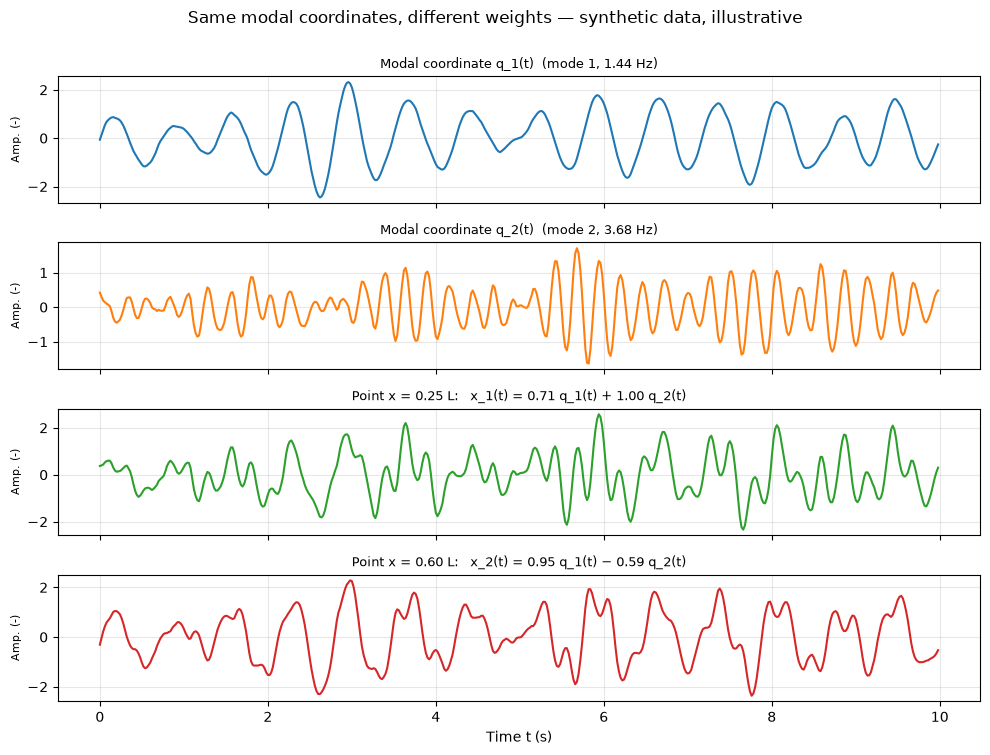

In [3]:
# Two points of a beam with 2 modes: different signals built from the same modal coordinates (illustrative)
rng_2m = np.random.default_rng(SEED + 1)
fs_2m = 50.0                                  # sampling rate, Hz
t_2m = np.arange(0, 10, 1 / fs_2m)            # time, s
q_2m = modal_response([1.44, 3.68], 0.02, fs_2m, t_2m.size, rng_2m) * np.array([[1.0], [0.6]])
x_pts = np.array([0.25, 0.6])                 # relative positions x/L of the two points
Phi_2m = beam_modes(x_pts, 2)                 # weights of each mode at each point
x_2m = Phi_2m @ q_2m                          # Eq. 3: x = Phi q

fig, axes = plt.subplots(4, 1, figsize=(10, 7.5), sharex=True)
axes[0].plot(t_2m, q_2m[0], color="C0")
axes[0].set_title("Modal coordinate q_1(t)  (mode 1, 1.44 Hz)", fontsize=9)
axes[1].plot(t_2m, q_2m[1], color="C1")
axes[1].set_title("Modal coordinate q_2(t)  (mode 2, 3.68 Hz)", fontsize=9)
for r, (xr, color) in enumerate(zip(x_pts, ["C2", "C3"])):
    w1, w2 = Phi_2m[r]
    axes[2 + r].plot(t_2m, x_2m[r], color=color)
    axes[2 + r].set_title(f"Point x = {xr:.2f} L:   x_{r + 1}(t) = {w1:.2f} q_1(t) {'+' if w2 >= 0 else '−'} "
                          f"{abs(w2):.2f} q_2(t)", fontsize=9)
for ax in axes:
    ax.set_ylabel("Amp. (-)", fontsize=8)
axes[-1].set_xlabel("Time t (s)")
fig.suptitle("Same modal coordinates, different weights — synthetic data, illustrative", y=1.0)
fig.tight_layout()
plt.show()

**Figura 2.** Coordenadas modales $q_1(t)$, $q_2(t)$ y respuesta en dos puntos de una viga (ilustrativo, datos sintéticos): $x_1$ y $x_2$ se ven distintas, pero las dos son sumas de las mismas $q_1$ y $q_2$ con los pesos de las formas modales en cada punto. En $x=0.6L$ el modo 2 entra con signo negativo, porque ese punto está del otro lado de su nodo (en $x=0.5L$).

**Ejemplo sintético.** La misma viga con tres modos (frecuencias de ejemplo 1.44, 3.68 y 4.66 Hz; amortiguamiento 2 %), medida en 17 puntos equiespaciados durante 1200 s a 20 Hz, con ruido de medición independiente en cada punto. Estos mismos datos se usan en el FDD (2.1.1.2).

Max |difference| off the diagonal: 0.0025
Mean difference on the diagonal:   0.0097  (noise variance = 0.0100)


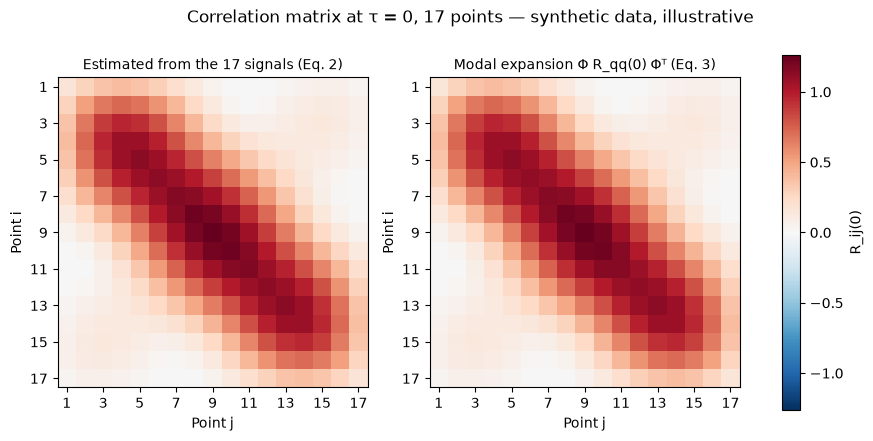

In [4]:
# Correlation matrix at tau = 0 of 17 points of a beam with 3 modes (illustrative; reused by the FDD)
rng_beam = np.random.default_rng(SEED + 2)
fs_beam = 20.0                                # sampling rate, Hz
n_beam = int(1200 * fs_beam)                  # 1200 s
f_true = np.array([1.44, 3.68, 4.66])         # example natural frequencies, Hz
amp_modes = np.array([1.0, 0.7, 0.5])         # RMS of each modal coordinate
x_rel = np.arange(1, 18) / 18                 # 17 equally spaced points, x/L
Phi_beam = beam_modes(x_rel, 3)               # true mode shapes, 17 x 3
q_beam = modal_response(f_true, 0.02, fs_beam, n_beam, rng_beam) * amp_modes[:, None]
noise_beam = 0.1 * rng_beam.standard_normal((17, n_beam))
x_beam = Phi_beam @ q_beam + noise_beam       # measured responses, 17 x N

R0 = x_beam @ x_beam.T / n_beam               # Eq. 2 with k = 0, all pairs
R0_modal = Phi_beam @ (q_beam @ q_beam.T / n_beam) @ Phi_beam.T   # Eq. 3: Phi R_qq(0) Phi^T
diff = R0 - R0_modal
off = ~np.eye(17, dtype=bool)
print(f"Max |difference| off the diagonal: {np.abs(diff[off]).max():.4f}")
print(f"Mean difference on the diagonal:   {np.diag(diff).mean():.4f}  (noise variance = {0.1 ** 2:.4f})")

vmax = np.abs(R0).max()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, M, title in zip(axes, [R0, R0_modal],
                        ["Estimated from the 17 signals (Eq. 2)", "Modal expansion Φ R_qq(0) Φᵀ (Eq. 3)"]):
    im = ax.imshow(M, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_xticks(range(0, 17, 2), labels=range(1, 18, 2))
    ax.set_yticks(range(0, 17, 2), labels=range(1, 18, 2))
    ax.set_xlabel("Point j")
    ax.set_ylabel("Point i")
    ax.set_title(title, fontsize=10)
    ax.grid(False)
fig.colorbar(im, ax=axes, label="R_ij(0)")
fig.suptitle("Correlation matrix at τ = 0, 17 points — synthetic data, illustrative")
plt.show()

**Figura 3.** Matriz de correlación en $\tau=0$ de los 17 puntos (ilustrativo, datos sintéticos): a la izquierda, calculada con las señales; a la derecha, con la expansión modal (Ec. 3). Las dos coinciden fuera de la diagonal: el ruido de cada punto no se comparte con los demás y se promedia. Solo la diagonal es un poco mayor a la izquierda, por la varianza del ruido de cada punto.

- Los puntos vecinos están muy correlacionados. Los puntos lejanos casi no, porque los modos 2 y 3 los mueven en sentidos opuestos y restan lo que aporta el modo 1.

*Paso a la frecuencia (Wiener–Khinchin).*

$$G_{ij}(\omega)=\int_{-\infty}^{\infty}R_{ij}(\tau)\,e^{-i\omega\tau}\,d\tau \tag{4}$$

- $G_{ij}(\omega)$: densidad espectral cruzada (CPSD) entre los puntos $i$ y $j$; con $i=j$ es la densidad espectral de potencia del punto $i$.
- $R_{ij}(\tau)$: correlación cruzada (Ec. 1).
- $\omega$: frecuencia angular, en rad/s ($\omega=2\pi f$).
- $i$ en el exponente: unidad imaginaria (no el índice del punto).

En palabras: la transformada de Fourier de la correlación dice cuánta energía comparten las dos señales en cada frecuencia. Con todos los pares sale la matriz espectral que usa el FDD ([2.1.1.2](#fdd)).

**Cómo se usa en drive-by** (referencia: Talebi-Kalaleh et al., 2025)

- Calculan la matriz de correlación $17\times 17$ entre las respuestas de los 17 puntos fijos, a partir de la matriz dispersa con los datos faltantes en cero.
- Es el primer paso del FDD.

**Ventajas**

- Promedia el ruido no correlacionado entre puntos.
- No necesita conocer la excitación.

**Desventajas**

- Necesita señales largas para que la estimación sea estable.
- Con datos faltantes, cada par de puntos tiene distinta cantidad de datos válidos.

**Artículos:** Talebi-Kalaleh et al. (2025).

> **Nota de fuentes.** La definición general de correlación cruzada, autocorrelación y Wiener–Khinchin es conocimiento general. Del artículo vienen: la matriz de correlación 17 × 17 de los puntos fijos (ec. 32) y su expansión modal (ec. 33).

**Entradas y salidas**

- **Entrada:** las señales de respuesta en $n$ puntos, sincronizadas en el tiempo.
- **Salida:** la matriz de correlación $n\times n$ para cada desplazamiento $\tau$.
- **Qué se obtiene o interpreta:**
  - Qué tan relacionadas están las vibraciones de cada par de puntos y con qué retraso.
  - Al pasarla a frecuencia, la matriz espectral que usa el FDD.

[↑ Volver al índice](#indice)

<a id="fdd"></a>
##### 2.1.1.2 FDD (Frequency Domain Decomposition)

FDD: *Frequency Domain Decomposition*, descomposición en el dominio de la frecuencia.

**Qué es**

- Es un método de identificación modal "solo con la salida" (*output-only*): usa las respuestas medidas en varios puntos, sin conocer la fuerza que excita al puente.
- Separa los modos en el dominio de la frecuencia, aplicando una SVD a la matriz espectral en cada frecuencia.
- Da a la vez las frecuencias naturales y las formas modales.

**Para qué se aplica**

- Para identificar frecuencias y formas modales con vibración ambiental o tráfico, cuando no se mide la excitación.
- Funciona bien aunque dos modos estén cerca en frecuencia.

**Cómo funciona**

1. Se calcula la correlación cruzada entre todos los pares de puntos ([2.1.1.1](#cross-correlation)).
2. Se pasa al dominio de la frecuencia: sale la matriz espectral $\mathbf{G}(\omega)$, de $n\times n$, en cada frecuencia.
3. En cada frecuencia se aplica una SVD a $\mathbf{G}(\omega)$ (la SVD se explica en [2.2.4.1](#svd-completed-matrix)).
4. Se grafica el primer valor singular contra la frecuencia. Sus picos son las frecuencias naturales.
5. En cada pico, el primer vector singular es la forma modal de ese modo.

**Idea clave:** cerca de una frecuencia natural domina un solo modo, así que la matriz espectral es casi de rango uno y la SVD la separa.

*Entrada en drive-by: la matriz dispersa* (ec. 31 del artículo).

$$\ddot{\mathbf{u}}_b(t)=\Gamma(t)\,\ddot{\mathbf{w}}_b(t) \tag{5}$$

- $\ddot{\mathbf{u}}_b(t)$: respuesta (aceleración) en los puntos fijos del puente, con los faltantes en cero.
- $\Gamma(t)$: matriz diagonal; su elemento $i$ vale 1 si en el instante $t$ hay dato válido en el punto $i$ y 0 si no.
- $\ddot{\mathbf{w}}_b(t)$: respuesta completa en los mismos puntos.

En palabras: la matriz dispersa es la respuesta completa con los datos que faltan puestos en cero.

*Paso 2: matriz espectral.*

$$\mathbf{G}(\omega)=\int_{-\infty}^{\infty}\mathbf{R}(\tau)\,e^{-i\omega\tau}\,d\tau \tag{6}$$

- $\mathbf{G}(\omega)$: matriz espectral $n\times n$; su elemento $(i,j)$ es la densidad espectral cruzada $G_{ij}(\omega)$ (Ec. 4).
- $\mathbf{R}(\tau)$: matriz de correlación (Ec. 3).
- $\omega$: frecuencia angular, en rad/s.

En palabras: es la Ec. 4 aplicada a todos los pares a la vez. En la práctica se estima con el método de Welch (promedio de los espectros de muchos tramos de la señal), que es equivalente.

*Paso 3: SVD en cada frecuencia* (ecs. 34–35 del artículo).

$$\mathbf{G}(j\omega)=\mathbf{U}(\omega)\,\Sigma(\omega)\,\mathbf{U}^{H}(\omega) \tag{7}$$

- $\mathbf{G}(j\omega)$: la matriz espectral de la Ec. 6 en la frecuencia $\omega$ ($j$: unidad imaginaria).
- $\mathbf{U}(\omega)$: matriz de vectores singulares, una columna $\mathbf{u}_r$ por componente.
- $\Sigma(\omega)$: matriz diagonal con los valores singulares, ordenados de mayor a menor ($\sigma_1\ge\sigma_2\ge\dots\ge 0$).
- $H$: transpuesta conjugada.

En palabras: en cada frecuencia, la matriz espectral se separa en componentes ordenadas de la más fuerte a la más débil. Como $\mathbf{G}$ es hermítica (igual a su transpuesta conjugada), la misma $\mathbf{U}$ aparece a los dos lados.

*Pasos 4–5: picos y formas modales.*

$$\mathbf{G}(\omega_k)\approx\sigma_1\,\mathbf{u}_1\mathbf{u}_1^{H},\qquad \phi_k\approx\mathbf{u}_1(\omega_k) \tag{8}$$

- $\omega_k$: frecuencia natural del modo $k$ (un pico de $\sigma_1$).
- $\sigma_1$: primer valor singular en $\omega_k$.
- $\mathbf{u}_1$: primer vector singular en $\omega_k$.
- $\phi_k$: forma modal del modo $k$ en los $n$ puntos.

En palabras: en el pico de un modo, la matriz espectral es casi un solo producto $\mathbf{u}_1\mathbf{u}_1^{H}$ (rango uno); por eso el primer vector singular es la forma modal y el segundo valor singular queda mucho más bajo.

Para comparar formas se usa el **MAC** (*Modal Assurance Criterion*, criterio de semejanza modal): $\text{MAC}(\phi,\mathbf{u})=|\phi^{H}\mathbf{u}|^2/\big((\phi^{H}\phi)(\mathbf{u}^{H}\mathbf{u})\big)$. Vale 1 si las dos formas son iguales salvo una escala, y 0 si no tienen nada en común.

**Ejemplo sintético.** Los 17 puntos de la viga de la Figura 3 (tres modos de 1.44, 3.68 y 4.66 Hz, excitados con ruido blanco, 1200 s a 20 Hz). Las frecuencias son valores de ejemplo: en una viga simplemente apoyada real crecerían con $k^2$. Los picos se buscan cerca de cada frecuencia verdadera ($\pm$0.15 Hz); en la práctica se escogen en la gráfica.

Frequency resolution: 0.0098 Hz
Mode 1: true 1.44 Hz, FDD 1.426 Hz (error 1.0 %), sigma_1/sigma_2 = 2327
Mode 2: true 3.68 Hz, FDD 3.691 Hz (error 0.3 %), sigma_1/sigma_2 = 164
Mode 3: true 4.66 Hz, FDD 4.648 Hz (error 0.2 %), sigma_1/sigma_2 = 82


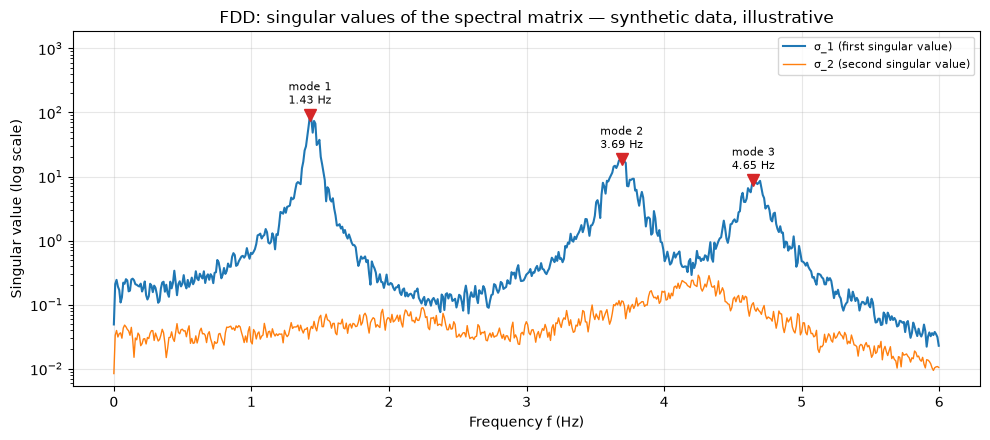

In [5]:
# FDD on the 17-point beam of Fig. 3: singular values of G(f) at each frequency (illustrative)
def fdd(x, fs, nperseg=2048):
    """Spectral matrix with Welch (Eq. 6) and its SVD at each frequency (Eq. 7)."""
    f, G = csd(x[:, None, :], x[None, :, :], fs=fs, nperseg=nperseg)   # G[i, j, f]
    U, s, _ = np.linalg.svd(np.moveaxis(G, -1, 0))                       # one SVD per frequency
    return f, s, U


def pick_peaks(f, s1, f_guess, half=0.15):
    """Index of the highest sigma_1 within +-half Hz of each guessed frequency."""
    return [np.flatnonzero(np.abs(f - fg) <= half)[np.argmax(s1[np.abs(f - fg) <= half])] for fg in f_guess]


f_fdd, s_fdd, U_fdd = fdd(x_beam, fs_beam)
peaks = pick_peaks(f_fdd, s_fdd[:, 0], f_true)
print(f"Frequency resolution: {f_fdd[1]:.4f} Hz")
for k, i in enumerate(peaks):
    print(f"Mode {k + 1}: true {f_true[k]:.2f} Hz, FDD {f_fdd[i]:.3f} Hz "
          f"(error {100 * abs(f_fdd[i] - f_true[k]) / f_true[k]:.1f} %), sigma_1/sigma_2 = {s_fdd[i, 0] / s_fdd[i, 1]:.0f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
keep = f_fdd <= 6
ax.semilogy(f_fdd[keep], s_fdd[keep, 0], color="C0", label="σ_1 (first singular value)")
ax.semilogy(f_fdd[keep], s_fdd[keep, 1], color="C1", lw=1, label="σ_2 (second singular value)")
for k, i in enumerate(peaks):
    ax.plot(f_fdd[i], s_fdd[i, 0], "v", color="C3", ms=8)
    ax.annotate(f"mode {k + 1}\n{f_fdd[i]:.2f} Hz", (f_fdd[i], s_fdd[i, 0]), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=8)
ax.set_xlabel("Frequency f (Hz)")
ax.set_ylabel("Singular value (log scale)")
ax.set_ylim(top=s_fdd[keep, 0].max() * 20)
ax.set_title("FDD: singular values of the spectral matrix — synthetic data, illustrative")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 4.** Primer y segundo valor singular de la matriz espectral contra la frecuencia (ilustrativo, datos sintéticos): $\sigma_1$ tiene un pico en cada frecuencia natural (1.44, 3.68 y 4.66 Hz). En los picos $\sigma_2$ queda muy por debajo de $\sigma_1$: la matriz es casi de rango uno (Ec. 8). Los modos 2 y 3 están cerca (1 Hz de diferencia) y aun así se separan.

- La frecuencia identificada difiere de la verdadera en 1 % o menos. El error viene de la resolución del espectro (0.01 Hz con tramos de 2048 muestras) y de la variabilidad de la estimación; las dos mejoran con señales más largas.

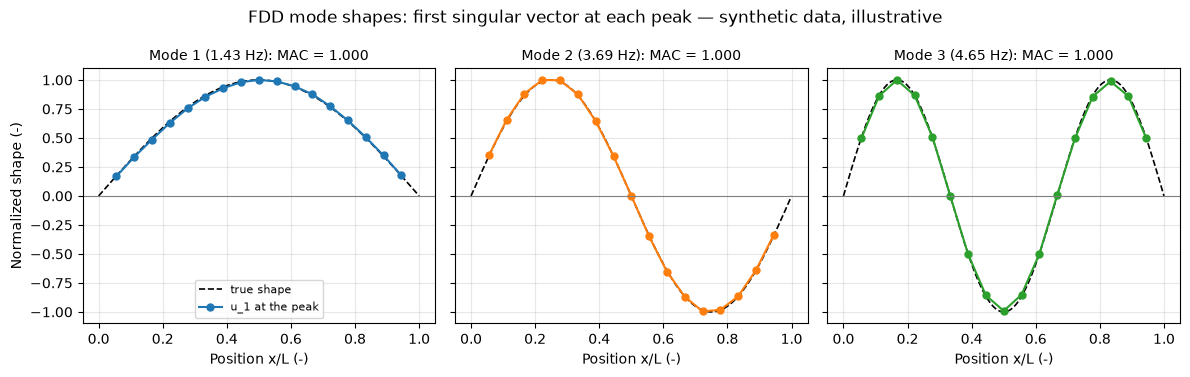

In [6]:
# First singular vector at each peak vs the true mode shape (illustrative)
x_fine = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for k, (ax, i) in enumerate(zip(axes, peaks)):
    u = real_shape(U_fdd[i, :, 0], Phi_beam[:, k])
    ax.plot(x_fine, np.sin((k + 1) * np.pi * x_fine), "k--", lw=1.2, label="true shape")
    ax.plot(x_rel, u, "o-", color=f"C{k}", ms=5, label="u_1 at the peak")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(f"Mode {k + 1} ({f_fdd[i]:.2f} Hz): MAC = {mac(Phi_beam[:, k], U_fdd[i, :, 0]):.3f}", fontsize=10)
    ax.set_xlabel("Position x/L (-)")
axes[0].set_ylabel("Normalized shape (-)")
axes[0].legend(loc="lower center", fontsize=8)
fig.suptitle("FDD mode shapes: first singular vector at each peak — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 5.** Primer vector singular en cada pico comparado con la forma modal verdadera (ilustrativo, datos sintéticos): los tres coinciden, con MAC cercano a 1. El vector singular es complejo; se gira para hacerlo real y se escala a un máximo de 1, porque el FDD da la forma, no su tamaño.

**Cómo se usa en drive-by** (referencia: Talebi-Kalaleh et al., 2025)

- Lo aplican directamente a la matriz dispersa de 17 puntos fijos × tiempo, con los datos faltantes en cero (Ec. 5), sin completarla.
- Salidas: un vector de frecuencias (picos del primer valor singular) y una matriz de formas modales de 17 filas × número de modos.
- Identificaron los tres primeros modos con MAC > 95 % y errores de frecuencia < 3 %, con 80 % de datos faltantes.

**Ejemplo sintético.** La misma viga con el 80 % de los datos en cero (Ec. 5): cada punto conserva bloques de 1 s escogidos al azar, el 20 % del tiempo. El patrón de faltantes es inventado; no reproduce el del artículo.

Missing data: 79.9 %
Mode 1: FDD 1.426 Hz (error 1.0 %), MAC complete 1.000, MAC 80 % missing 0.975
Mode 2: FDD 3.682 Hz (error 0.0 %), MAC complete 1.000, MAC 80 % missing 0.953
Mode 3: FDD 4.648 Hz (error 0.2 %), MAC complete 1.000, MAC 80 % missing 0.961


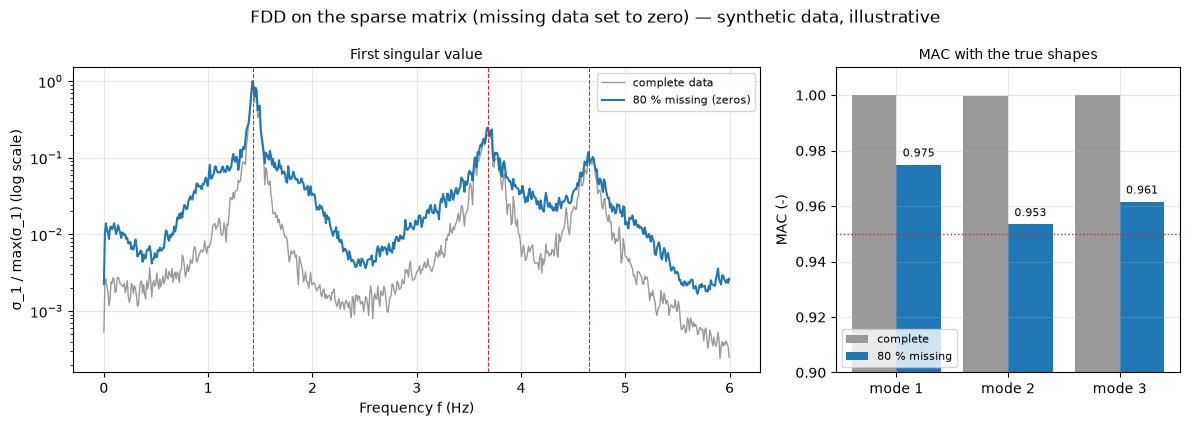

In [7]:
# FDD with 80 % of the data set to zero (sparse matrix of Eq. 5, illustrative)
rng_mask = np.random.default_rng(SEED + 3)
block = int(1.0 * fs_beam)                                   # 1 s blocks
n_blocks = int(np.ceil(n_beam / block))
Gamma = np.repeat(rng_mask.random((17, n_blocks)) < 0.2, block, axis=1)[:, :n_beam]   # 1 = valid sample
x_sparse = x_beam * Gamma                                    # Eq. 5: missing data set to zero
print(f"Missing data: {100 * (1 - Gamma.mean()):.1f} %")

f_sp, s_sp, U_sp = fdd(x_sparse, fs_beam)
peaks_sp = pick_peaks(f_sp, s_sp[:, 0], f_true)
mac_full = [mac(Phi_beam[:, k], U_fdd[i, :, 0]) for k, i in enumerate(peaks)]
mac_sp = [mac(Phi_beam[:, k], U_sp[i, :, 0]) for k, i in enumerate(peaks_sp)]
for k, i in enumerate(peaks_sp):
    print(f"Mode {k + 1}: FDD {f_sp[i]:.3f} Hz (error {100 * abs(f_sp[i] - f_true[k]) / f_true[k]:.1f} %), "
          f"MAC complete {mac_full[k]:.3f}, MAC 80 % missing {mac_sp[k]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [2, 1]})
keep = f_fdd <= 6
axes[0].semilogy(f_fdd[keep], s_fdd[keep, 0] / s_fdd[keep, 0].max(), color="0.6", lw=1, label="complete data")
axes[0].semilogy(f_sp[keep], s_sp[keep, 0] / s_sp[keep, 0].max(), color="C0", label="80 % missing (zeros)")
for i in peaks_sp:
    axes[0].axvline(f_sp[i], color="C3", ls="--", lw=0.8)
axes[0].set_xlabel("Frequency f (Hz)")
axes[0].set_ylabel("σ_1 / max(σ_1) (log scale)")
axes[0].set_title("First singular value", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
pos_bar = np.arange(3)
axes[1].bar(pos_bar - 0.2, mac_full, 0.4, color="0.6", label="complete")
axes[1].bar(pos_bar + 0.2, mac_sp, 0.4, color="C0", label="80 % missing")
for p, m in zip(pos_bar + 0.2, mac_sp):
    axes[1].text(p, m + 0.003, f"{m:.3f}", ha="center", fontsize=8)
axes[1].axhline(0.95, color="C3", ls=":", lw=1)
axes[1].set_xticks(pos_bar, labels=["mode 1", "mode 2", "mode 3"])
axes[1].set_ylim(0.9, 1.01)
axes[1].set_ylabel("MAC (-)")
axes[1].set_title("MAC with the true shapes", fontsize=10)
axes[1].legend(loc="lower left", fontsize=8)
fig.suptitle("FDD on the sparse matrix (missing data set to zero) — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 6.** FDD con el 80 % de los datos en cero (ilustrativo, datos sintéticos): a la izquierda, el primer valor singular (normalizado) con datos completos y con faltantes; a la derecha, el MAC de las formas en cada pico. Los tres picos siguen en las mismas frecuencias y el MAC baja un poco, pero queda por encima de 0.95 (línea punteada). Con faltantes, el piso entre picos sube: los ceros agregan energía repartida en todas las frecuencias.

**Ventajas**

- No necesita medir la excitación.
- Sencillo y rápido: Fourier y una SVD por frecuencia.
- Separa modos cercanos.
- Da frecuencias y formas modales en un solo procedimiento.

**Desventajas**

- Supone excitación de ruido blanco, amortiguamiento bajo y formas modales ortogonales.
- La precisión de la frecuencia depende de la resolución del espectro (longitud de la señal).
- La versión básica no da el amortiguamiento (existe la variante EFDD, *Enhanced FDD*, que sí lo estima).
- Necesita señales simultáneas en varios puntos.

**Pregunta abierta**

> ¿Por qué la matriz incompleta, con los faltantes en cero, no afecta los resultados del FDD?

**Artículos:** Talebi-Kalaleh et al. (2025).

> **Nota de fuentes.** La explicación general del FDD, sus supuestos y la variante EFDD es conocimiento general. Del artículo vienen: su aplicación directa a la matriz dispersa con faltantes en cero (ecs. 31 a 35), las salidas (vector de frecuencias y matriz de 17 filas) y los resultados del caso base.

**Entradas y salidas**

- **Entrada:**
  - Las respuestas en $n$ puntos, sincronizadas (en *drive-by*, la matriz dispersa con faltantes en cero).
  - Su frecuencia de muestreo.
- **Salida:** los valores y vectores singulares de la matriz espectral en cada frecuencia.
- **Qué se obtiene o interpreta:**
  - Los picos del primer valor singular dan las frecuencias naturales.
  - El primer vector singular en cada pico da la forma modal.

[↑ Volver al índice](#indice)

---

<a id="mode-shapes"></a>
### 2.2 Mode shapes

<a id="mode-shapes-signal-decomposition"></a>
#### 2.2.2 Signal decomposition

<a id="emd-hilbert"></a>
##### 2.2.2.1 EMD + Hilbert transform

**Qué es**

- La EMD (*Empirical Mode Decomposition*, descomposición empírica en modos) separa una señal en componentes llamadas IMF (*Intrinsic Mode Functions*, funciones de modo intrínseco), de la oscilación más rápida a la más lenta, más una tendencia final.
- Es **adaptativa**: no usa una base fija (como el seno de Fourier o la wavelet madre); las componentes salen de la propia señal.
- La **transformada de Hilbert** se aplica después a cada IMF para obtener su amplitud y su frecuencia en cada instante.
- Juntas forman la transformada de Hilbert-Huang (HHT, *Hilbert-Huang transform*).

**Qué es una IMF** (dos condiciones)

1. El número de extremos y el número de cruces por cero difieren como máximo en uno.
2. En cada instante, la media entre la envolvente superior y la inferior es cero.

Con eso, cada IMF es una oscilación "limpia", parecida a un seno, pero con amplitud y frecuencia que pueden cambiar en el tiempo.

**Para qué se aplica**

- En señales **no lineales y no estacionarias**, donde las frecuencias o amplitudes cambian en el tiempo.
- En *drive-by*: para aislar la componente de un modo del puente y seguir cómo cambia su amplitud mientras el vehículo avanza.

**Cómo funciona**

EMD (proceso de *sifting*, "cernido"):

1. Se buscan los máximos y mínimos locales de la señal.
2. Se unen los máximos con un spline cúbico (envolvente superior) y los mínimos con otro (envolvente inferior).
3. Se calcula la media de las dos envolventes y se resta de la señal.
4. Se repite sobre el resultado hasta que cumpla las condiciones de IMF (criterio de parada). Esa es la primera IMF, la más rápida.
5. Se resta la IMF de la señal original y se repite todo sobre lo que queda (el residuo), para sacar la siguiente IMF, más lenta.
6. Se para cuando el residuo ya no oscila (es monótono): esa es la tendencia.

Hilbert:

7. A cada IMF se le aplica la transformada de Hilbert, que desfasa cada componente un cuarto de periodo ($\pi/2$).
8. Con la IMF y su transformada se forma la señal analítica, de donde salen la amplitud instantánea (envolvente) y la frecuencia instantánea.

*Resultado de la EMD (pasos 1–6).*

$$x(t)=\sum_{i=1}^{n} c_i(t) + r_n(t) \tag{9}$$

- $x(t)$: señal medida.
- $c_i(t)$: la IMF número $i$ ($i=1$ es la más rápida).
- $n$: número de IMFs.
- $r_n(t)$: residuo final o tendencia (ya no oscila).

En palabras: la señal es exactamente la suma de sus IMFs más la tendencia; la EMD no pierde nada, solo reparte la señal en capas.

*Un paso de sifting (pasos 2–3).*

$$m(t)=\frac{e_{\max}(t)+e_{\min}(t)}{2},\qquad h(t)=x(t)-m(t) \tag{10}$$

- $e_{\max}(t)$: envolvente superior (spline cúbico por los máximos).
- $e_{\min}(t)$: envolvente inferior (spline cúbico por los mínimos).
- $m(t)$: media de las dos envolventes.
- $h(t)$: candidato a IMF, lo que queda al quitar la media.

En palabras: se quita a la señal la línea que pasa por el centro de sus oscilaciones; lo que queda oscila alrededor de cero.

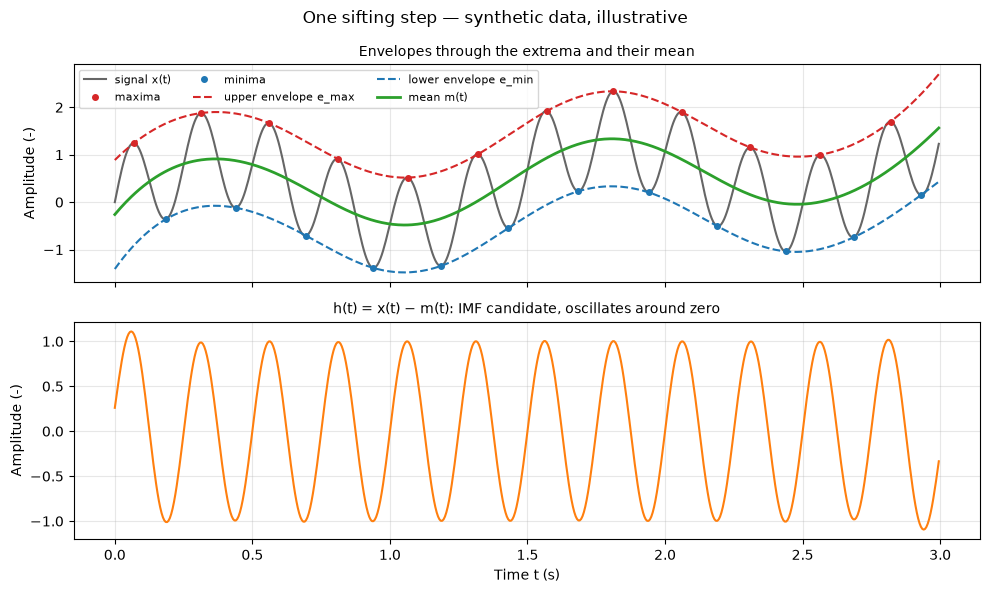

In [8]:
# One sifting step on a synthetic signal (illustrative)
fs_s = 200.0                            # sampling rate, Hz
t_s = np.arange(0, 3, 1 / fs_s)         # time, s
x_s = np.sin(2 * np.pi * 4 * t_s) + 0.8 * np.sin(2 * np.pi * 0.7 * t_s) + 0.3 * t_s

i_max = argrelextrema(x_s, np.greater)[0]     # local maxima
i_min = argrelextrema(x_s, np.less)[0]        # local minima
e_max = CubicSpline(t_s[i_max], x_s[i_max])(t_s)   # upper envelope
e_min = CubicSpline(t_s[i_min], x_s[i_min])(t_s)   # lower envelope
m_s = (e_max + e_min) / 2                     # mean envelope (Eq. 10)
h_s = x_s - m_s                               # IMF candidate (Eq. 10)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax = axes[0]
ax.plot(t_s, x_s, color="0.4", label="signal x(t)")
ax.plot(t_s[i_max], x_s[i_max], "o", color="C3", ms=4, label="maxima")
ax.plot(t_s[i_min], x_s[i_min], "o", color="C0", ms=4, label="minima")
ax.plot(t_s, e_max, "--", color="C3", label="upper envelope e_max")
ax.plot(t_s, e_min, "--", color="C0", label="lower envelope e_min")
ax.plot(t_s, m_s, color="C2", lw=2, label="mean m(t)")
ax.set_ylabel("Amplitude (-)")
ax.set_title("Envelopes through the extrema and their mean", fontsize=10)
ax.legend(loc="upper left", fontsize=8, ncol=3)
axes[1].plot(t_s, h_s, color="C1")
axes[1].set_ylabel("Amplitude (-)")
axes[1].set_xlabel("Time t (s)")
axes[1].set_title("h(t) = x(t) − m(t): IMF candidate, oscillates around zero", fontsize=10)
fig.suptitle("One sifting step — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 7.** Un paso de *sifting* sobre una señal sintética (ilustrativo): arriba, la señal con sus máximos y mínimos, las dos envolventes (splines cúbicos) y su media; abajo, la señal menos la media, que ya oscila alrededor de cero. Cerca de los bordes las envolventes se doblan porque no hay extremos más allá: es el efecto de borde.

*Descomposición completa (pasos 4–6).* Repitiendo el *sifting* hasta cumplir las condiciones de IMF, y luego sobre cada residuo, se obtiene la Ec. 9. La señal de prueba suma una oscilación rápida de 8 Hz con amplitud variable, una lenta de 1.2 Hz, una tendencia lineal y ruido.

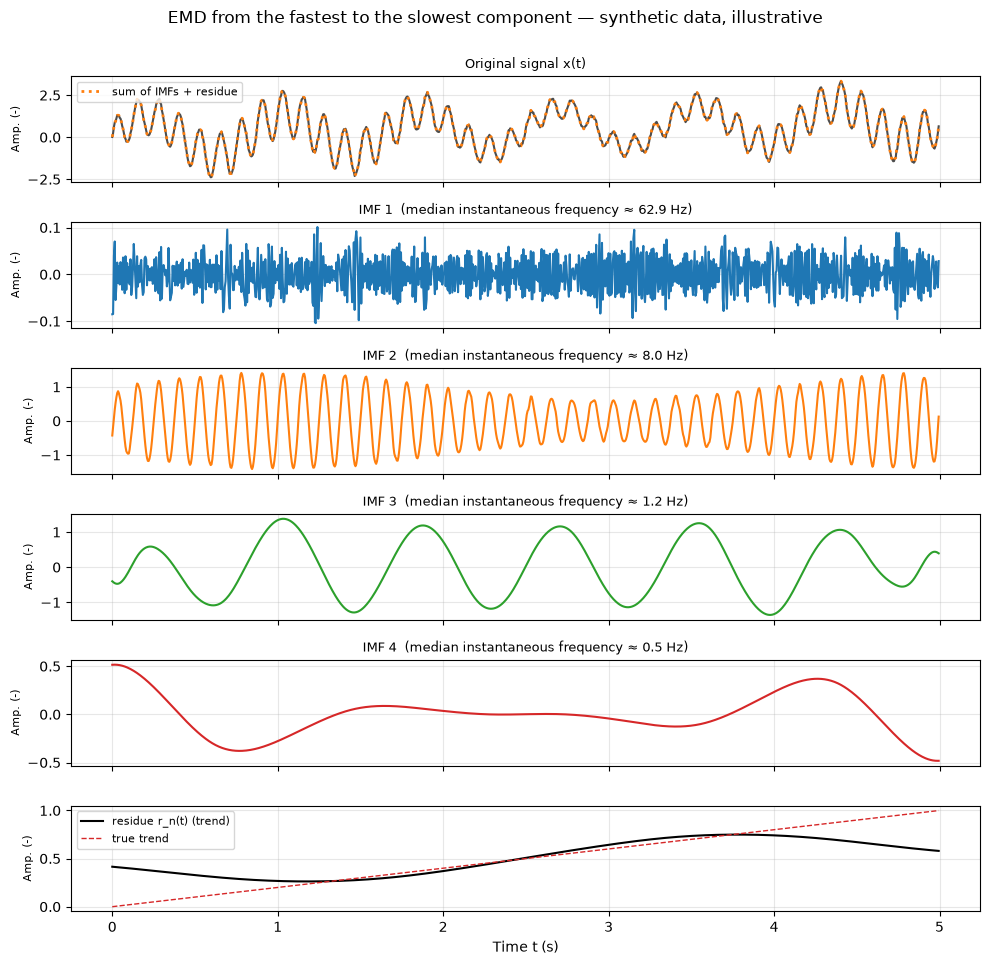

Number of IMFs: 4
Max reconstruction error |x - (sum c_i + r_n)|: 1.1e-16


In [9]:
# Full EMD of a synthetic signal (illustrative)
rng_emd = np.random.default_rng(SEED)   # own generator: keeps the other sections unchanged
fs_e = 200.0                            # sampling rate, Hz
t_e = np.arange(0, 5, 1 / fs_e)         # time, s
fast = (1 + 0.4 * np.sin(2 * np.pi * 0.25 * t_e)) * np.sin(2 * np.pi * 8 * t_e)   # 8 Hz, varying amplitude
slow = 1.2 * np.sin(2 * np.pi * 1.2 * t_e)                                        # 1.2 Hz
trend = 0.2 * t_e
x_e = fast + slow + trend + 0.05 * rng_emd.standard_normal(t_e.size)

emd = EMD()
emd.emd(x_e, t_e)
imfs, residue = emd.get_imfs_and_residue()
n_imf = imfs.shape[0]
reconstruction = imfs.sum(axis=0) + residue    # Eq. 9

fig, axes = plt.subplots(n_imf + 2, 1, figsize=(10, 1.6 * (n_imf + 2)), sharex=True)
axes[0].plot(t_e, x_e, color="0.3")
axes[0].set_title("Original signal x(t)", fontsize=9)
for i in range(n_imf):
    _, f_i = instantaneous_attributes(imfs[i], fs_e)
    axes[i + 1].plot(t_e, imfs[i], color=f"C{i}")
    axes[i + 1].set_title(f"IMF {i + 1}  (median instantaneous frequency ≈ {np.median(f_i):.1f} Hz)", fontsize=9)
axes[-1].plot(t_e, residue, color="k", label="residue r_n(t) (trend)")
axes[-1].plot(t_e, trend, "--", color="C3", lw=1, label="true trend")
axes[-1].legend(loc="upper left", fontsize=8)
for ax in axes:
    ax.set_ylabel("Amp. (-)", fontsize=8)
axes[-1].set_xlabel("Time t (s)")
axes[0].plot(t_e, reconstruction, ":", color="C1", lw=2, label="sum of IMFs + residue")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("EMD from the fastest to the slowest component — synthetic data, illustrative", y=1.0)
fig.tight_layout()
plt.show()
print(f"Number of IMFs: {n_imf}")
print(f"Max reconstruction error |x - (sum c_i + r_n)|: {np.max(np.abs(x_e - reconstruction)):.1e}")

**Figura 8.** EMD de una señal sintética (ilustrativo): de arriba abajo, la señal original (con la reconstrucción punteada encima), las IMFs de la más rápida a la más lenta y el residuo comparado con la tendencia verdadera.

- La IMF 1 recoge el ruido, la IMF 2 la oscilación de 8 Hz y la IMF 3 la de 1.2 Hz. La IMF 4 es una oscilación lenta y pequeña que sobra de la tendencia y de los bordes.
- El residuo se aparta de la tendencia verdadera porque parte de ella quedó en la IMF 4: es un caso de mezcla de modos, que se repite en señales cortas.
- La suma de todas las IMFs más el residuo reproduce la señal original (error del orden de la precisión numérica): es la Ec. 9.

*Hilbert (pasos 7–8).*

$$\mathcal{H}[c](t)=\frac{1}{\pi}\,\mathrm{PV}\!\int_{-\infty}^{\infty}\frac{c(\tau)}{t-\tau}\,d\tau \tag{11}$$

- $\mathcal{H}[c](t)$: transformada de Hilbert de la IMF $c$ en el instante $t$.
- $c(\tau)$: la IMF, evaluada en cada instante $\tau$ de la integral.
- $\mathrm{PV}$: valor principal de Cauchy; la integral se evalúa excluyendo simétricamente el punto $\tau=t$, donde el denominador se anula.
- $1/\pi$: constante de normalización.

En palabras: produce una copia de la IMF desfasada un cuarto de periodo ($\pi/2$) en cada componente; un coseno se vuelve seno.

$$z(t)=c(t)+i\,\mathcal{H}[c](t)=A(t)\,e^{i\theta(t)} \tag{12}$$

$$A(t)=\sqrt{c(t)^2+\mathcal{H}[c](t)^2},\qquad f(t)=\frac{1}{2\pi}\frac{d\theta}{dt} \tag{13}$$

- $z(t)$: señal analítica (compleja): la IMF como parte real y su transformada de Hilbert como parte imaginaria.
- $i$: unidad imaginaria.
- $A(t)$: amplitud instantánea o envolvente.
- $\theta(t)$: fase instantánea, en rad.
- $f(t)$: frecuencia instantánea, en Hz.

En palabras: la IMF y su copia desfasada son como las dos coordenadas de un punto que gira; el radio del giro es la amplitud y la velocidad del giro es la frecuencia, en cada instante.

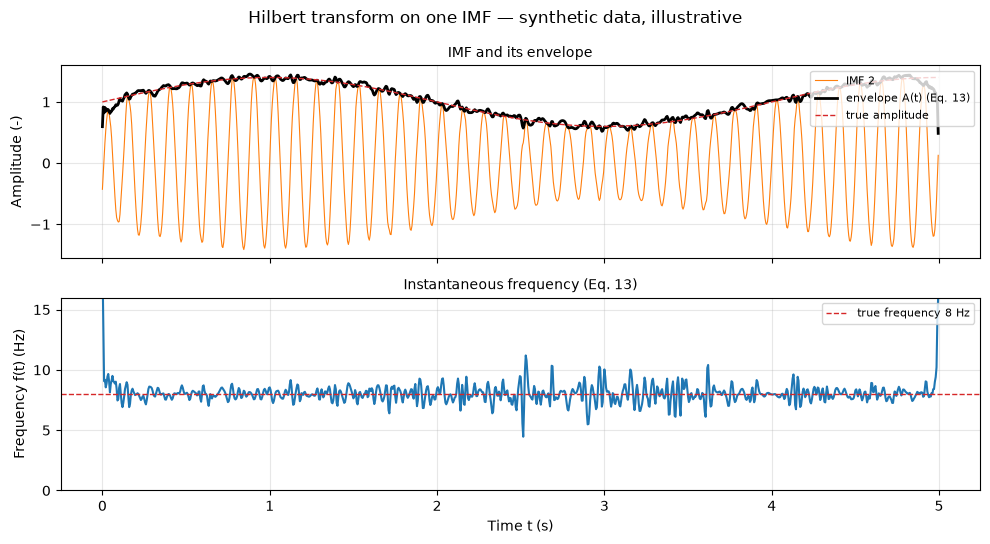

In [10]:
# Hilbert transform on the 8 Hz IMF of Fig. 8 (illustrative)
f_target = 8.0
medians = [np.median(instantaneous_attributes(c, fs_e)[1]) for c in imfs]
k_fast = int(np.argmin(np.abs(np.array(medians) - f_target)))   # IMF closest to 8 Hz
amp_fast, freq_fast = instantaneous_attributes(imfs[k_fast], fs_e)
true_env = 1 + 0.4 * np.sin(2 * np.pi * 0.25 * t_e)

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes[0].plot(t_e, imfs[k_fast], color="C1", lw=0.8, label=f"IMF {k_fast + 1}")
axes[0].plot(t_e, amp_fast, color="k", lw=2, label="envelope A(t) (Eq. 13)")
axes[0].plot(t_e, true_env, "--", color="C3", lw=1, label="true amplitude")
axes[0].set_ylabel("Amplitude (-)")
axes[0].set_title("IMF and its envelope", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[1].plot(t_e, freq_fast, color="C0")
axes[1].axhline(f_target, color="C3", ls="--", lw=1, label="true frequency 8 Hz")
axes[1].set_ylim(0, 16)
axes[1].set_ylabel("Frequency f(t) (Hz)")
axes[1].set_xlabel("Time t (s)")
axes[1].set_title("Instantaneous frequency (Eq. 13)", fontsize=10)
axes[1].legend(loc="upper right", fontsize=8)
fig.suptitle("Hilbert transform on one IMF — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 9.** Transformada de Hilbert sobre la IMF de 8 Hz (ilustrativo): arriba, la IMF con su envolvente $A(t)$, que sigue la amplitud verdadera; abajo, la frecuencia instantánea $f(t)$, que se mantiene cerca de 8 Hz.

- En los extremos la frecuencia se dispara y la envolvente se deforma: es el efecto de borde de la EMD y de la transformada de Hilbert.

**Cómo se usa para la forma modal** (referencia: Malekjafarian y OBrien, 2017)

- Se escoge la IMF cuya frecuencia instantánea se mantiene cerca de la frecuencia del modo buscado (en el artículo, la frecuencia a la que se sintonizó un excitador en el vehículo).
- Su amplitud instantánea, expresada contra la posición del vehículo, indica cuánto se mueve ese modo en cada punto.
- En el artículo, la envolvente se suaviza con un promedio móvil y se recortan los extremos. Luego se usa en el reescalado entre ejes para construir la forma modal (eso es otro paso del mapa, 2.2.4; aquí solo se menciona).

**Ejemplo sintético.** Un vehículo cruza una viga simplemente apoyada de $L=15$ m a $v=2$ m/s (cruce de 7.5 s). La señal es:

$x(t)=|\phi(v\,t)|\cos(2\pi f_b t)+\text{componente del vehículo}+\text{ruido}$

- $f_b=5.65$ Hz y $\phi(x)=\sin(\pi x/L)$: primer modo de la viga.
- La componente del vehículo es una oscilación de 1.5 Hz (valor inventado para el ejemplo).
- La luz, la velocidad y $f_b$ coinciden con el caso que estudia el artículo, pero la señal es sintética: no reproduce sus datos ni sus resultados.
- Promedio móvil de 0.5 s y recorte de 0.5 s (1 m) en cada extremo: valores escogidos para el ejemplo.

Median instantaneous frequency of each IMF (Hz): [32.07  5.7   1.51  0.98  0.52]
Selected IMF: 2 (closest to f_b = 5.65 Hz)
RMS error vs |phi| on the trimmed part: 0.047


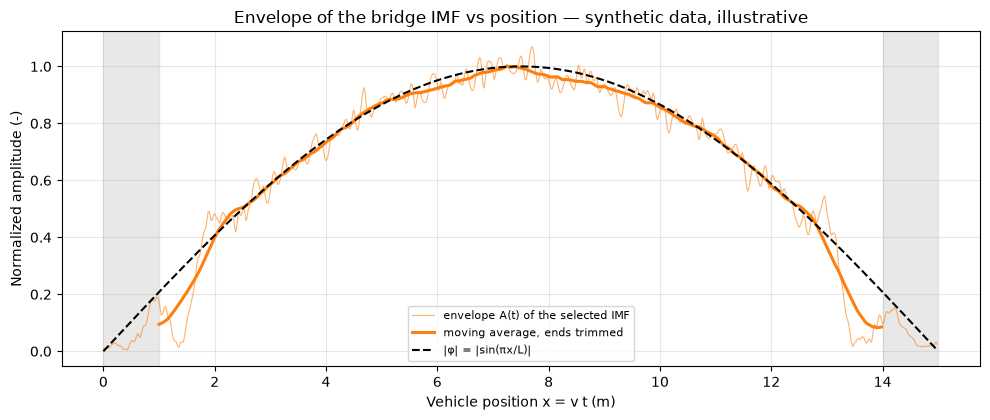

In [11]:
# Drive-by example: 15 m simply supported beam crossed at 2 m/s (illustrative)
rng_db = np.random.default_rng(SEED)
L_b = 15.0                              # span length, m
v_b = 2.0                               # vehicle speed, m/s
f_b = 5.65                              # bridge mode 1 frequency, Hz
f_veh = 1.5                             # vehicle component frequency, Hz (made up)
fs_b = 100.0                            # sampling rate, Hz

t_b = np.arange(0, L_b / v_b, 1 / fs_b) # time, s
pos_b = v_b * t_b                       # vehicle position, m
phi_b = np.sin(np.pi * pos_b / L_b)     # mode 1 shape
x_b = (np.abs(phi_b) * np.cos(2 * np.pi * f_b * t_b)
       + 0.8 * np.sin(2 * np.pi * f_veh * t_b)
       + 0.05 * rng_db.standard_normal(t_b.size))

emd_b = EMD()
emd_b.emd(x_b, t_b)
imfs_b, _ = emd_b.get_imfs_and_residue()
medians_b = np.array([np.median(instantaneous_attributes(c, fs_b)[1]) for c in imfs_b])
k_b = int(np.argmin(np.abs(medians_b - f_b)))          # IMF closest to the bridge frequency
amp_b, _ = instantaneous_attributes(imfs_b[k_b], fs_b)

win = int(0.5 * fs_b)                                  # moving-average window: 0.5 s
amp_smooth = np.convolve(amp_b, np.ones(win) / win, mode="same")
inner = slice(win, -win)                               # trim 0.5 s at each end
amp_norm = amp_smooth / amp_smooth[inner].max()

print("Median instantaneous frequency of each IMF (Hz):", np.round(medians_b, 2))
print(f"Selected IMF: {k_b + 1} (closest to f_b = {f_b} Hz)")
rms = np.sqrt(np.mean((amp_norm[inner] - np.abs(phi_b[inner])) ** 2))
print(f"RMS error vs |phi| on the trimmed part: {rms:.3f}")

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(pos_b, amp_b / amp_smooth[inner].max(), color="C1", lw=0.8, alpha=0.6, label="envelope A(t) of the selected IMF")
ax.plot(pos_b[inner], amp_norm[inner], color="C1", lw=2.2, label="moving average, ends trimmed")
ax.plot(pos_b, np.abs(phi_b), "k--", lw=1.5, label="|φ| = |sin(πx/L)|")
for edge in [(0, pos_b[win]), (pos_b[-win], L_b)]:
    ax.axvspan(*edge, color="0.85", alpha=0.6)
ax.set_xlabel("Vehicle position x = v t (m)")
ax.set_ylabel("Normalized amplitude (-)")
ax.set_title("Envelope of the bridge IMF vs position — synthetic data, illustrative")
ax.legend(loc="lower center", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 10.** Envolvente de la IMF del puente contra la posición del vehículo, comparada con $|\phi|$ (ilustrativo, datos sintéticos): la EMD separa el modo de 5.65 Hz de la componente del vehículo, y su envolvente suavizada sigue la forma del primer modo. Las franjas grises son los extremos recortados, donde actúa el efecto de borde.

- La envolvente no tiene signo; con el primer modo no se nota porque $\phi$ es positiva en toda la luz.

**Ventajas**

- Adaptativa: no necesita escoger una base ni una wavelet madre.
- Funciona con señales no lineales y no estacionarias.
- Da amplitud y frecuencia en cada instante, con muy buena resolución en el tiempo.

**Desventajas**

- **Mezcla de modos:** una IMF puede contener oscilaciones de escalas distintas, o una misma oscilación puede repartirse entre dos IMFs.
- **Efectos de borde:** los splines se deforman en los extremos de la señal (por eso en el artículo se recortan los extremos).
- Sensible al ruido; el resultado depende del criterio de parada.
- No tiene una base matemática cerrada; es un algoritmo empírico.
- Hilbert solo da una frecuencia con sentido físico si la IMF tiene una sola componente (banda estrecha).
- Para formas modales hay que saber qué frecuencia buscar.
- Existen variantes que reducen la mezcla de modos, como EEMD (*Ensemble EMD*) y CEEMDAN (*Complete Ensemble EMD with Adaptive Noise*).

**Pregunta abierta**

> La EMD da IMFs parecidas a ondas seno, y por eso Hilbert funciona. Pero una señal real viene de muchas fuentes, y no todas son de tipo seno. Si alguna no lo es, ¿queda en el residuo o se mezcla en las IMFs y las distorsiona?

**Artículos:** Malekjafarian y OBrien (2017).

> **Nota de fuentes.** La explicación general de la EMD, las condiciones de IMF, la transformada de Hilbert, la mezcla de modos y las variantes EEMD/CEEMDAN es conocimiento general, no del artículo. Del artículo vienen: la descomposición en IMFs de la más rápida a la más lenta, el uso de Hilbert para la frecuencia instantánea y la selección de la IMF cercana a la frecuencia de excitación, y la envolvente contra la posición suavizada con promedio móvil y recortada en los extremos.

**Entradas y salidas**

- **Entrada:**
  - Una señal de aceleración contra tiempo, de un solo canal, con su frecuencia de muestreo.
  - El criterio de parada del *sifting* y, si se quiere, el número máximo de IMFs.
  - Para formas modales, además: la posición del vehículo en cada instante y la frecuencia del modo que se busca.
- **Salida:**
  - Un conjunto de IMFs $c_i(t)$ más un residuo.
  - Para cada IMF, su amplitud instantánea $A_i(t)$ y su frecuencia instantánea $f_i(t)$.
- **Qué se obtiene o interpreta:**
  - Qué oscilaciones componen la señal y cómo cambia la frecuencia de cada una en el tiempo.
  - Cuál IMF corresponde al modo del puente (la que se mantiene cerca de su frecuencia).
  - La envolvente de esa IMF contra la posición: cómo cambia la amplitud del modo a lo largo del puente, que es la base para construir la forma modal.

[↑ Volver al índice](#indice)

<a id="fdd-mode-shapes"></a>
##### 2.2.2.2 FDD (Frequency Domain Decomposition)

Se explica en [2.1.1.2](#fdd). Aquí, además de las frecuencias, se usa el vector singular en cada pico como forma modal.

<a id="wavelet-sswt"></a>
##### 2.2.2.3 Wavelet transform (SSWT)

SSWT: *synchrosqueezed wavelet transform*, transformada wavelet sincro-comprimida. Parte de la CWT (*continuous wavelet transform*, transformada wavelet continua).

**Qué es**

- La transformada wavelet descompone una señal en frecuencias, como Fourier, pero además dice **en qué momento** aparece cada frecuencia.
- La versión sincro-comprimida (SSWT) concentra mejor la energía en cada frecuencia, por lo que el mapa sale más nítido.

**Para qué se aplica**

- En señales **cortas o no estacionarias**, donde las frecuencias o sus amplitudes cambian en el tiempo.
- En *drive-by*: para ver cómo cambia la amplitud de una frecuencia del puente mientras el carro avanza, y con eso construir la forma modal.

**Cómo funciona**

1. Se escoge una **wavelet madre**: una onda corta que oscila y se apaga hacia los lados. La más usada en vibraciones es la Morlet.
2. Para cada frecuencia, la wavelet se **estira o se comprime** y se coloca en cada instante de la señal.
3. En cada posición se **multiplica punto por punto** con la señal y se suma: si la señal oscila a esa frecuencia en ese momento, el resultado es grande; si no, es casi cero.
4. Así se llena un **mapa frecuencia contra tiempo**, donde cada celda es una amplitud.

*Paso 1: la wavelet madre Morlet.*

$$\psi(t)=\pi^{-1/4}\,e^{i\omega_0 t}\,e^{-t^{2}/2} \tag{14}$$

- $\psi(t)$: wavelet madre Morlet (valor complejo) en el instante $t$.
- $t$: tiempo de la wavelet madre, en s.
- $i$: unidad imaginaria.
- $\omega_0$: frecuencia central (adimensional); fija cuántas oscilaciones caben dentro de la campana. Valor típico: $\omega_0 \approx 6$.
- $e^{i\omega_0 t}=\cos(\omega_0 t)+i\,\sin(\omega_0 t)$: la **oscilación**.
- $e^{-t^{2}/2}$: la **campana** gaussiana que apaga la oscilación hacia los lados.
- $\pi^{-1/4}$: constante para que la wavelet tenga energía unitaria.

En palabras: una onda que oscila a $\omega_0$ multiplicada por una campana; oscila en el centro y se apaga hacia los lados.

*Paso 2: estirar o comprimir.* La wavelet se usa como $\psi\!\left(\frac{t-b}{a}\right)$: la escala $a$ la estira o la comprime y $b$ la desplaza en el tiempo. La frecuencia a la que oscila depende de la escala:

$$f=\frac{\omega_0}{2\pi a} \tag{15}$$

- $f$: frecuencia a la que oscila la wavelet estirada, en Hz.
- $a$: escala, en s; $a>1$ estira la wavelet y $a<1$ la comprime.
- $\omega_0$: frecuencia central de la Morlet (Ec. 14).
- $2\pi$: pasa de radianes por segundo a ciclos por segundo (Hz).

En palabras: escala grande = wavelet estirada = frecuencia baja; escala pequeña = wavelet comprimida = frecuencia alta.

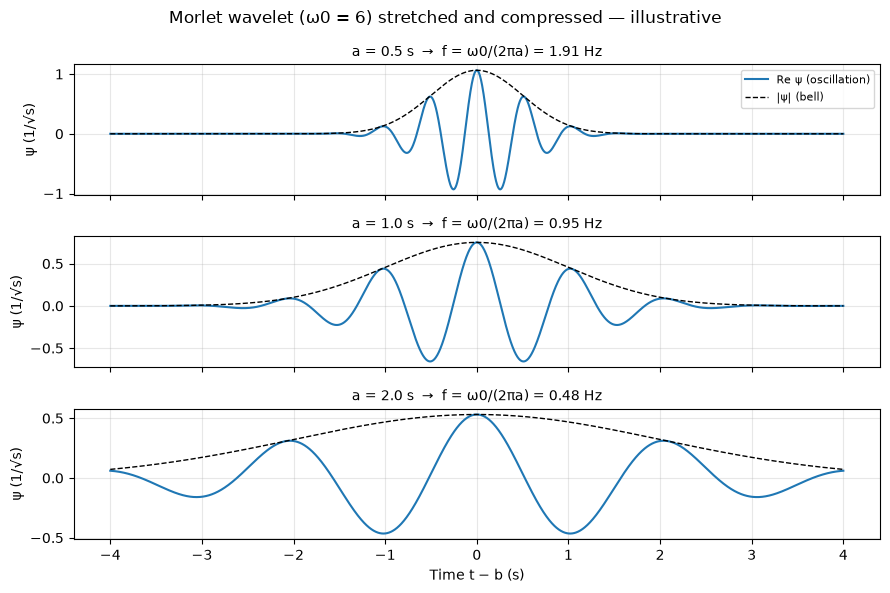

In [12]:
# Real part of the Morlet wavelet at three scales (illustrative)
w0 = 6.0
t = np.linspace(-4, 4, 2000)            # time around the wavelet center, s
scales = [0.5, 1.0, 2.0]                # scale a, s

fig, axes = plt.subplots(len(scales), 1, figsize=(9, 6), sharex=True)
for ax, a in zip(axes, scales):
    psi = scaled_wavelet(t, a, b=0.0, w0=w0)
    f = w0 / (2 * np.pi * a)            # Eq. 15
    ax.plot(t, psi.real, color="C0", label="Re ψ (oscillation)")
    ax.plot(t, np.abs(psi), "k--", lw=1, label="|ψ| (bell)")
    ax.set_ylabel("ψ (1/√s)")
    ax.set_title(f"a = {a} s  →  f = ω0/(2πa) = {f:.2f} Hz", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("Time t − b (s)")
fig.suptitle("Morlet wavelet (ω0 = 6) stretched and compressed — illustrative")
fig.tight_layout()
plt.show()

**Figura 11.** Parte real de la wavelet Morlet a tres escalas (ilustrativo): con $a$ pequeña la wavelet se comprime y oscila rápido (frecuencia alta); con $a$ grande se estira y oscila lento (frecuencia baja). La línea discontinua es la campana que la apaga hacia los lados.

*Paso 3: multiplicar y sumar.* Para una escala $a$ y un instante $b$, el coeficiente wavelet es:

$$W(a,b)=\frac{1}{\sqrt{a}}\int_{-\infty}^{\infty} x(t)\,\psi^{*}\!\left(\frac{t-b}{a}\right)dt \tag{16}$$

- $W(a,b)$: coeficiente wavelet (complejo) en la escala $a$ y el instante $b$; $|W(a,b)|$ es la **amplitud** de esa celda del mapa.
- $x(t)$: señal medida.
- $\psi$: wavelet madre (Ec. 14); $^{*}$ indica el conjugado complejo.
- $a$: escala, en s (fija la frecuencia, Ec. 15).
- $b$: desplazamiento en el tiempo: instante donde se centra la wavelet, en s.
- $1/\sqrt{a}$: normalización para que la wavelet tenga la misma energía en todas las escalas.
- $\int \dots\, dt$: multiplicar punto por punto la señal por la wavelet y sumar.

En palabras: mide cuánto se parece la señal, alrededor del instante $b$, a una oscilación de la frecuencia que corresponde a la escala $a$.

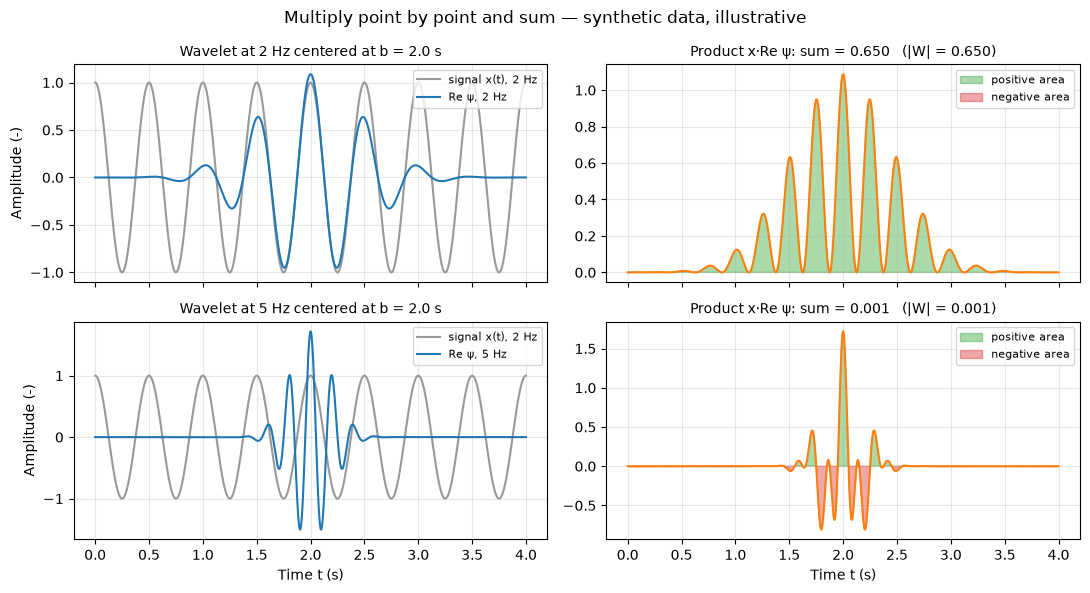

In [13]:
# "Multiply and sum": cosine at 2 Hz vs wavelets at 2 Hz and 5 Hz (illustrative)
dt = 0.001
t = np.arange(0, 4, dt)                 # time, s
f_signal = 2.0                          # signal frequency, Hz
x = np.cos(2 * np.pi * f_signal * t)
b = 2.0                                 # wavelet center, s

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for row, f_wav in enumerate([2.0, 5.0]):
    a = scale_for_freq(f_wav, w0=6.0)
    psi = scaled_wavelet(t, a, b, w0=6.0)
    product = x * psi.real
    total = product.sum() * dt                       # real part of Eq. 16
    W = (x * np.conj(psi)).sum() * dt                # full complex Eq. 16
    ax_l, ax_r = axes[row]
    ax_l.plot(t, x, color="0.6", label="signal x(t), 2 Hz")
    ax_l.plot(t, psi.real, color="C0", label=f"Re ψ, {f_wav:.0f} Hz")
    ax_l.set_ylabel("Amplitude (-)")
    ax_l.set_title(f"Wavelet at {f_wav:.0f} Hz centered at b = {b} s", fontsize=10)
    ax_l.legend(loc="upper right", fontsize=8)
    ax_r.plot(t, product, color="C1")
    ax_r.fill_between(t, product, where=product > 0, color="C2", alpha=0.4, label="positive area")
    ax_r.fill_between(t, product, where=product < 0, color="C3", alpha=0.4, label="negative area")
    ax_r.set_title(f"Product x·Re ψ: sum = {total:.3f}   (|W| = {abs(W):.3f})", fontsize=10)
    ax_r.legend(loc="upper right", fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Time t (s)")
fig.suptitle("Multiply point by point and sum — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 12.** Multiplicar y sumar (ilustrativo, datos sintéticos): con la wavelet a la misma frecuencia de la señal (2 Hz, arriba) el producto es casi siempre positivo y la suma es grande; con la wavelet a otra frecuencia (5 Hz, abajo) el producto alterna signo, las áreas se cancelan y la suma es casi cero.

- La suma de la gráfica usa solo la parte real de $\psi$; $|W|$ usa la wavelet compleja completa (Ec. 16). Con la wavelet compleja la amplitud $|W|$ no depende de si la wavelet queda en fase con la señal.

*Paso 4: el mapa.* Repetir la Ec. 16 para muchas escalas $a$ (frecuencias, Ec. 15) y muchos instantes $b$ llena el mapa $|W(a,b)|$. En la CWT la energía de una frecuencia queda **repartida** en una franja ancha de escalas vecinas. La SSWT la reasigna en dos pasos:

$$\omega(a,b)=\frac{-i\,\partial_b W(a,b)}{W(a,b)} \tag{17}$$

- $\omega(a,b)$: frecuencia instantánea de la celda $(a,b)$, en rad/s: la frecuencia a la que realmente oscila la señal en esa celda.
- $\partial_b W(a,b)$: derivada del coeficiente respecto al tiempo $b$.
- $W(a,b)$: coeficiente wavelet (Ec. 16).
- $i$: unidad imaginaria.

En palabras: la fase de $W$ gira a la velocidad de la oscilación de la señal; derivarla en el tiempo da esa frecuencia, aunque la celda esté en una escala vecina.

$$T(f_l,b)=\sum_{a\,:\;\omega(a,b)/2\pi\,\approx\,f_l} W(a,b) \tag{18}$$

- $T(f_l,b)$: valor del mapa sincro-comprimido en la frecuencia $f_l$ (Hz) y el instante $b$.
- $f_l$: cada una de las frecuencias (filas) del mapa nuevo.
- La suma recorre solo las escalas $a$ cuya frecuencia instantánea (Ec. 17, pasada a Hz) cae en $f_l$.
- Expresión conceptual: se omiten las constantes de normalización.

En palabras: la energía de todas las celdas que "dicen" oscilar a $f_l$ se junta en la fila $f_l$; la franja ancha de la CWT se comprime en una línea delgada, y por eso el mapa sale más nítido.

**Ejemplo sintético.** Un carro cruza una viga simplemente apoyada de $L=100$ m a $v=20$ m/s (cruce de 5 s). Mide la vibración del puente en el segundo modo, con $f=1.3$ Hz y forma modal $\phi(x)=\sin(2\pi x/L)$:

$x(t)=|\phi(v\,t)|\cos(2\pi f t)+\text{ruido}$

- La amplitud que ve el carro sube y baja según la forma modal en el punto donde está.
- El eje de tiempo se pasa a posición con $x = v\,t$ (lo que en la práctica da el GPS; ver el apartado siguiente).
- Se usa la Morlet analítica de `ssqueezepy` con $\omega_0 = 3$ (en `ssqueezepy`, `mu`) en vez de 6: la wavelet es más corta y sigue mejor los cambios de amplitud en un cruce de solo 5 s, a cambio de menos resolución en frecuencia. Es una elección para este ejemplo, no un valor del artículo.

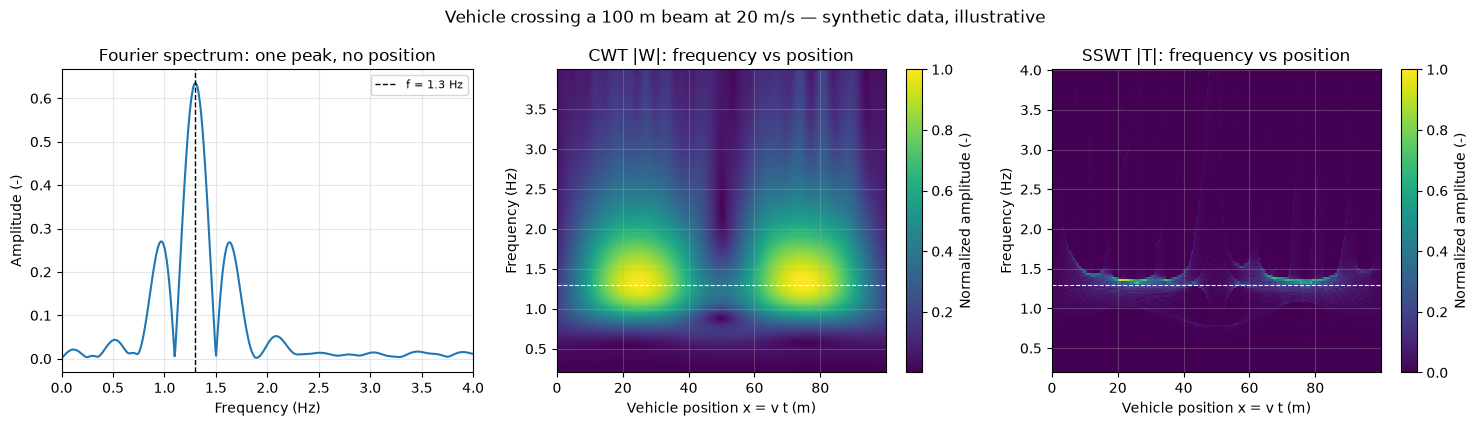

In [14]:
# Synthetic drive-by signal: vehicle crossing a 100 m simply supported beam
L = 100.0                               # span length, m
v = 20.0                                # vehicle speed, m/s
f_mode = 1.3                            # frequency of mode 2, Hz
fs = 100.0                              # sampling rate, Hz
noise_std = 0.1                         # noise standard deviation (-)

t = np.arange(0, L / v, 1 / fs)         # time, s
pos = v * t                             # vehicle position, m (x = v t)
phi_true = np.sin(2 * np.pi * pos / L)  # mode 2 shape
x = np.abs(phi_true) * np.cos(2 * np.pi * f_mode * t) + noise_std * rng.standard_normal(t.size)

# Fourier amplitude spectrum (zero-padded for a smooth curve)
n_fft = 2 ** 14
spec = np.abs(np.fft.rfft(x, n=n_fft)) * 2 / t.size
freqs_fft = np.fft.rfftfreq(n_fft, 1 / fs)

# CWT and SSWT with the analytic Morlet wavelet
wavelet = Wavelet(("morlet", {"mu": 3}))
Wx, scales_cwt = cwt(x, wavelet, fs=fs, nv=32, padtype="zero")
freqs_cwt = scale_to_freq(scales_cwt, wavelet, N=2 ** 14, fs=fs)   # Eq. 15 for this wavelet
Tx, _, freqs_ssq, _ = ssq_cwt(x, wavelet, fs=fs, nv=32, padtype="zero")

f_max = 4.0                             # upper frequency shown, Hz
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].plot(freqs_fft, spec, color="C0")
axes[0].axvline(f_mode, color="k", ls="--", lw=1, label=f"f = {f_mode} Hz")
axes[0].set_xlim(0, f_max)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Amplitude (-)")
axes[0].set_title("Fourier spectrum: one peak, no position")
axes[0].legend(fontsize=8)

for ax, Z, fr, name in [(axes[1], Wx, freqs_cwt, "CWT |W|"), (axes[2], Tx, freqs_ssq, "SSWT |T|")]:
    A = np.abs(Z) / np.abs(Z).max()     # normalized amplitude
    keep = fr <= f_max
    mesh = ax.pcolormesh(pos, fr[keep], A[keep], shading="auto", cmap="viridis")
    ax.axhline(f_mode, color="w", ls="--", lw=0.8)
    ax.set_xlabel("Vehicle position x = v t (m)")
    ax.set_ylabel("Frequency (Hz)")
    ax.set_title(f"{name}: frequency vs position")
    fig.colorbar(mesh, ax=ax, label="Normalized amplitude (-)")
fig.suptitle("Vehicle crossing a 100 m beam at 20 m/s — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 13.** Señal sintética de un carro que cruza una viga de 100 m (ilustrativo): el espectro de Fourier (izquierda) solo muestra un pico cerca de 1.3 Hz, sin decir dónde está; la CWT (centro) muestra esa frecuencia a lo largo de la posición, pero en una franja ancha; la SSWT (derecha) la concentra en una línea delgada y se ve dónde la amplitud crece o cae a cero.

- En los dos mapas la amplitud baja casi a cero en $x \approx 50$ m: ahí está el nodo del segundo modo.
- Fourier no puede mostrarlo porque promedia toda la señal; la wavelet sí, porque mira la señal por ventanas.
- La línea de la SSWT queda ligeramente por encima de 1.3 Hz (≈ 1.35 Hz); por eso, para la forma modal se promedia una banda alrededor de la frecuencia y no una sola fila del mapa.

**Cómo se usa para la forma modal**

- Con el **GPS** se cambia el tiempo por la posición del carro: $x = v\,t$ si la velocidad es constante; en general, la posición GPS en cada instante.
- Se toma la **franja de la frecuencia del modo** (aquí $1.3 \pm 0.3$ Hz) y se promedia su amplitud a lo largo del puente. La curva resultante, normalizada a máximo 1, es la forma modal estimada.

RMS error vs |phi|: 0.053
RMS error vs phi (with sign): 0.981


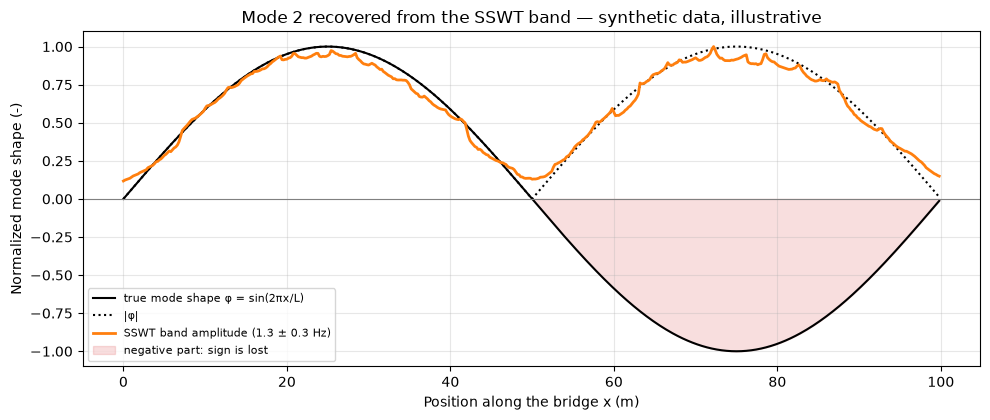

In [15]:
# Mode shape from the SSWT: mean amplitude in the band around the mode frequency
half_band = 0.3                         # half width of the frequency band, Hz
band = np.abs(freqs_ssq - f_mode) <= half_band
amp_band = np.abs(Tx[band]).mean(axis=0)
phi_est = amp_band / amp_band.max()     # normalized to max = 1

rms_abs = np.sqrt(np.mean((phi_est - np.abs(phi_true)) ** 2))
rms_signed = np.sqrt(np.mean((phi_est - phi_true) ** 2))
print(f"RMS error vs |phi|: {rms_abs:.3f}")
print(f"RMS error vs phi (with sign): {rms_signed:.3f}")

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(pos, phi_true, "k-", lw=1.5, label="true mode shape φ = sin(2πx/L)")
ax.plot(pos, np.abs(phi_true), "k:", lw=1.5, label="|φ|")
ax.plot(pos, phi_est, color="C1", lw=2, label=f"SSWT band amplitude ({f_mode} ± {half_band} Hz)")
ax.fill_between(pos, phi_true, 0, where=phi_true < 0, color="C3", alpha=0.15,
                label="negative part: sign is lost")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("Position along the bridge x (m)")
ax.set_ylabel("Normalized mode shape (-)")
ax.set_title("Mode 2 recovered from the SSWT band — synthetic data, illustrative")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 14.** Amplitud promedio de la SSWT en la banda de 1.3 Hz a lo largo de la posición, comparada con la forma modal verdadera (ilustrativo, datos sintéticos): la curva sigue a $|\phi|$, pero en el tramo de 50 a 100 m, donde la forma real es negativa, sale positiva. Se recupera la forma en valor absoluto y se pierde el signo.

- El error RMS respecto a $|\phi|$ es pequeño; respecto a $\phi$ con signo es grande, porque todo el tramo negativo sale reflejado hacia arriba.
- Para recuperar el signo hace falta otra información (por ejemplo, la fase); la amplitud por sí sola no la tiene.

**Ventajas**

- Funciona con señales cortas y no estacionarias.
- Da frecuencia y posición a la vez.

**Desventajas**

- Para formas modales hay que conocer de antemano la frecuencia del modo.
- La amplitud no tiene signo: la forma modal sale en valor absoluto.
- No separa la respuesta del puente de la del vehículo.

**Artículos:** Dabbaghchian et al. (2025).

> **Nota de fuentes.** La explicación general de cómo funciona la wavelet es conocimiento general, no del artículo. Del artículo vienen: el uso de la SSWT con wavelet madre Morlet analítica y los límites para formas modales (frecuencia conocida de antemano, forma modal absoluta).

**Entradas y salidas**

- **Entrada:**
  - Una señal de aceleración contra tiempo, de un solo canal (vertical u horizontal), con su frecuencia de muestreo.
  - La wavelet madre escogida (por ejemplo, Morlet).
  - Para formas modales, además: la posición del vehículo en cada instante (GPS) y la frecuencia del modo, conocida de antemano.
- **Salida:**
  - Un mapa tiempo-frecuencia de coeficientes complejos $W(a,b)$; su magnitud $|W|$ es la amplitud de cada celda.
  - Con el GPS, el mismo mapa en función de la posición sobre el puente.
- **Qué se obtiene o interpreta:**
  - Qué frecuencias tiene la señal y en qué momento aparecen.
  - Cómo cambia la amplitud de una frecuencia a lo largo del recorrido.
  - Tomando la franja de la frecuencia del modo y promediando muchos viajes, la forma modal en valor absoluto (sin signo).

[↑ Volver al índice](#indice)

<a id="build-shape"></a>
#### 2.2.4 Build the shape along the bridge

<a id="svd-completed-matrix"></a>
##### 2.2.4.1 SVD of the completed matrix

SVD: *Singular Value Decomposition*, descomposición en valores singulares.

**Qué es**

- La SVD descompone cualquier matriz en tres: direcciones en filas ($\mathbf{U}$), pesos ($\Sigma$) y direcciones en columnas ($\mathbf{V}$).
- Los valores singulares, ordenados de mayor a menor, dicen cuánto aporta cada componente.
- Está muy relacionada con el PCA (*Principal Component Analysis*, análisis de componentes principales): las columnas de $\mathbf{U}$ son las direcciones principales de los datos.

**Para qué se aplica**

- Para encontrar los patrones dominantes de una matriz y reducir el ruido quedándose con las primeras componentes.
- En el FDD, para separar los modos en cada frecuencia ([2.1.1.2](#fdd)).
- En *drive-by*: para extraer las formas modales de una matriz de respuesta espacio–tiempo.

**Cómo funciona**

1. Se arma la matriz de datos: una fila por punto del puente y una columna por instante de tiempo.
2. Se aplica la SVD: $\mathbf{D}=\mathbf{U}\Sigma\mathbf{V}^{T}$.
3. Cada columna de $\mathbf{U}$ es un patrón espacial (en un puente, una forma a lo largo de los puntos); cada fila de $\mathbf{V}^{T}$ es cómo varía ese patrón en el tiempo; $\sigma_i$ es su peso.
4. Como la respuesta del puente es una suma de modos, la matriz tiene rango bajo: unas pocas componentes explican casi todo.
5. Las primeras columnas de $\mathbf{U}$ se toman como formas modales.

*La descomposición (pasos 2–3).*

$$\mathbf{D}=\mathbf{U}\,\Sigma\,\mathbf{V}^{T}=\sum_{i=1}^{r}\sigma_i\,\mathbf{u}_i\,\mathbf{v}_i^{T} \tag{19}$$

- $\mathbf{D}$: matriz de datos ($n$ puntos × $N$ instantes).
- $\mathbf{U}$, $\mathbf{V}$: matrices ortogonales; sus columnas tienen norma 1 y son perpendiculares entre sí.
- $\Sigma$: matriz diagonal con los valores singulares $\sigma_1\ge\sigma_2\ge\dots\ge 0$.
- $r$: rango de $\mathbf{D}$ (número de valores singulares distintos de cero).
- $\mathbf{u}_i$: patrón espacial $i$ (columna $i$ de $\mathbf{U}$, $n$ valores).
- $\mathbf{v}_i$: variación en el tiempo del patrón $i$ (columna $i$ de $\mathbf{V}$, $N$ valores).

En palabras: la matriz es una suma de capas; cada capa es un patrón espacial multiplicado por su variación en el tiempo y por un peso $\sigma_i$, y las capas van de la más fuerte a la más débil.

*La respuesta del puente (paso 4).*

$$\mathbf{D}\approx\Phi\,\mathbf{Q} \tag{20}$$

- $\Phi$: formas modales ($n\times m$, una por columna).
- $\mathbf{Q}$: coordenadas modales en el tiempo ($m\times N$, una fila por modo).
- $m$: número de modos que responden.

En palabras: cada columna de $\mathbf{D}$ (la "foto" del puente en un instante) es una combinación de las mismas $m$ formas modales. Por eso $\mathbf{D}$ tiene rango cercano a $m$, aunque tenga cientos de columnas. Si las formas modales son ortogonales y las coordenadas modales no están correlacionadas y tienen energías distintas, las columnas de $\mathbf{U}$ coinciden con las formas modales normalizadas.

**Ejemplo sintético.** Matriz de 10 puntos × 677 instantes (el tamaño que usa Mei et al., 2021) de una viga simplemente apoyada con tres modos ($\sin(k\pi x/L)$; 1.44, 3.68 y 4.66 Hz como ejemplo; amplitudes 1, 0.5 y 0.25), muestreada a 100 Hz, más ruido. La matriz está completa: el ejemplo no simula el *soft imputing*.

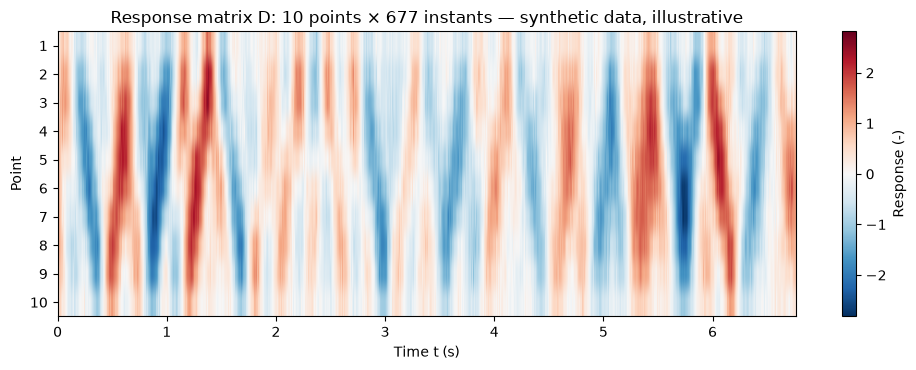

In [16]:
# Synthetic 10 x 677 response matrix: beam with 3 modes plus noise (illustrative)
rng_svd = np.random.default_rng(SEED + 4)
fs_d = 100.0                                   # sampling rate, Hz
n_t = 677                                      # time samples (same size as Mei et al., 2021)
x_d = np.arange(1, 11) / 11                    # 10 equally spaced points, x/L
Phi_d = beam_modes(x_d, 3)                     # true mode shapes, 10 x 3
Q_d = modal_response(f_true, 0.02, fs_d, n_t, rng_svd) * np.array([[1.0], [0.5], [0.25]])
D_clean = Phi_d @ Q_d                          # Eq. 20: D = Phi Q
D_mat = D_clean + 0.1 * rng_svd.standard_normal(D_clean.shape)
t_d = np.arange(n_t) / fs_d

fig, ax = plt.subplots(figsize=(10, 3.8))
vmax = np.abs(D_mat).max()
im = ax.imshow(D_mat, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax,
               extent=[t_d[0], t_d[-1], 10.5, 0.5])
ax.set_yticks(range(1, 11))
ax.set_xlabel("Time t (s)")
ax.set_ylabel("Point")
ax.set_title("Response matrix D: 10 points × 677 instants — synthetic data, illustrative")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Response (-)")
fig.tight_layout()
plt.show()

**Figura 15.** Matriz sintética de 10 puntos × 677 instantes (ilustrativo): cada fila es la respuesta de un punto y cada columna es la "foto" del puente en un instante. Las franjas inclinadas muestran que los puntos no se mueven todos a la vez: es la mezcla de los tres modos. El ruido casi no se ve, porque es pequeño frente a la respuesta.

*Aproximación de rango $k$.*

$$\mathbf{D}_k=\sum_{i=1}^{k}\sigma_i\,\mathbf{u}_i\,\mathbf{v}_i^{T} \tag{21}$$

- $\mathbf{D}_k$: matriz reconstruida solo con las primeras $k$ componentes.
- $k$: número de componentes que se conservan.
- $\sigma_i$, $\mathbf{u}_i$, $\mathbf{v}_i$: como en la Ec. 19.

En palabras: con $k$ igual al número de modos se conserva la respuesta y se descarta el ruido, que queda repartido en las componentes pequeñas.

Singular values: [60.9 30.6 15.4  2.7  2.6  2.6  2.5  2.5  2.5  2.4]
Energy in the first 3 components: 99.1 %
Relative error vs the noise-free matrix: D 11.7 %, D_3 6.6 %


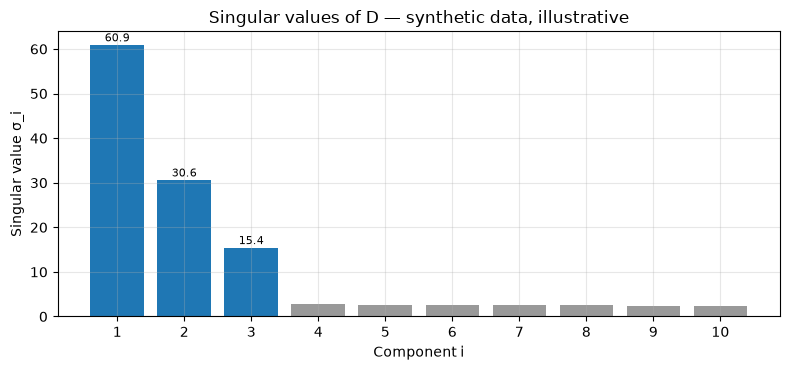

In [17]:
# Singular values of D: three large ones (the modes) and the rest small (noise)
U_d, s_d, Vt_d = np.linalg.svd(D_mat, full_matrices=False)     # Eq. 19
D_3 = (U_d[:, :3] * s_d[:3]) @ Vt_d[:3]                         # Eq. 21 with k = 3
energy_3 = np.sum(s_d[:3] ** 2) / np.sum(s_d ** 2)
err_raw = np.linalg.norm(D_mat - D_clean) / np.linalg.norm(D_clean)
err_3 = np.linalg.norm(D_3 - D_clean) / np.linalg.norm(D_clean)
print("Singular values:", np.round(s_d, 1))
print(f"Energy in the first 3 components: {100 * energy_3:.1f} %")
print(f"Relative error vs the noise-free matrix: D {100 * err_raw:.1f} %, D_3 {100 * err_3:.1f} %")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(np.arange(1, 11), s_d, color=["C0"] * 3 + ["0.6"] * 7)
for i, s in enumerate(s_d[:3]):
    ax.text(i + 1, s + 0.8, f"{s:.1f}", ha="center", fontsize=8)
ax.set_xticks(np.arange(1, 11))
ax.set_xlabel("Component i")
ax.set_ylabel("Singular value σ_i")
ax.set_title("Singular values of D — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 16.** Valores singulares de la matriz de la Figura 15 (ilustrativo, datos sintéticos): tres son grandes (los tres modos, en azul) y los otros siete son pequeños y parecidos entre sí (el ruido). El salto entre $\sigma_3$ y $\sigma_4$ dice cuántos modos hay.

- La reconstrucción con las tres primeras componentes (Ec. 21) se acerca más a la matriz sin ruido que la matriz medida: la SVD quita la mayor parte del ruido.

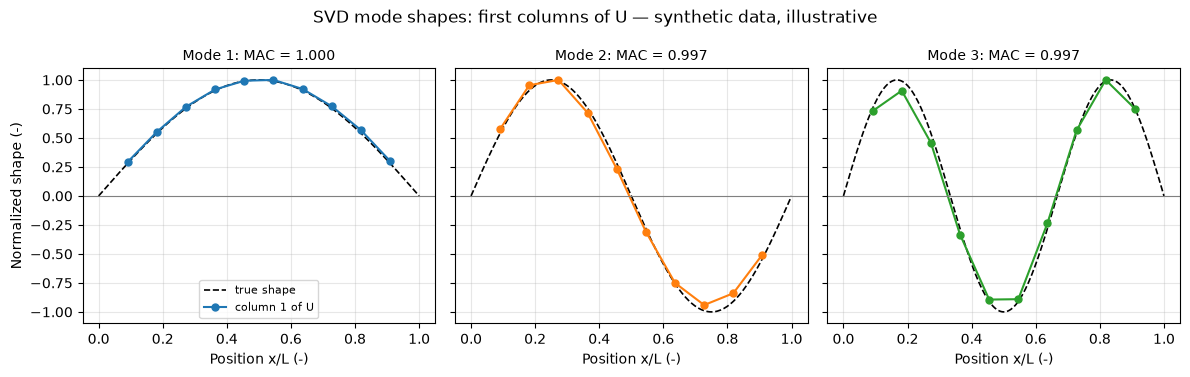

In [18]:
# First three columns of U vs the true mode shapes (illustrative)
x_fine = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for k, ax in enumerate(axes):
    u = U_d[:, k] / np.max(np.abs(U_d[:, k]))
    u = u if np.dot(u, Phi_d[:, k]) >= 0 else -u              # the sign of a singular vector is arbitrary
    ax.plot(x_fine, np.sin((k + 1) * np.pi * x_fine), "k--", lw=1.2, label="true shape")
    ax.plot(x_d, u, "o-", color=f"C{k}", ms=5, label=f"column {k + 1} of U")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(f"Mode {k + 1}: MAC = {mac(Phi_d[:, k], U_d[:, k]):.3f}", fontsize=10)
    ax.set_xlabel("Position x/L (-)")
axes[0].set_ylabel("Normalized shape (-)")
axes[0].legend(loc="lower center", fontsize=8)
fig.suptitle("SVD mode shapes: first columns of U — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 17.** Las tres primeras columnas de $\mathbf{U}$ comparadas con las formas modales verdaderas (ilustrativo, datos sintéticos): coinciden, con MAC cercano a 1. Se escalan a un máximo de 1 y se les ajusta el signo, porque la SVD da la forma pero no su tamaño ni su signo.

- En este ejemplo los senos son exactamente ortogonales en 10 puntos equiespaciados y los modos tienen energías muy distintas: es el caso favorable para la SVD.

**Cómo se usa en drive-by** (referencia: Mei et al., 2021)

- Arman la matriz de desplazamientos de 10 puntos fijos × tiempo ($10\times 677$), la completan con *soft imputing* (completado de matrices que rellena los huecos suponiendo que la matriz es de rango bajo) y le aplican la SVD.
- Las columnas de $\mathbf{U}$ dan las formas modales.
- Sin rugosidad y con 2 MMPs (*moving measurement points*, puntos de medición móviles), el MAC fue de 1.000 / 0.998 / 0.977 para los tres modos.

**Ventajas**

- Siempre existe, para cualquier matriz.
- Separa los patrones dominantes del ruido.
- No necesita conocer la excitación.

**Desventajas**

- Necesita la matriz completa (por eso Mei primero la rellena con *soft imputing*).
- Si dos modos tienen energía parecida, las componentes pueden mezclarlos.
- Las componentes son ortogonales; si las formas modales reales no lo son, no coinciden exactamente.
- No da frecuencias por sí sola; hay que analizar las filas de $\mathbf{V}^{T}$.

**Artículos:** Mei et al. (2021). También se usa dentro del FDD de Talebi-Kalaleh et al. (2025), en cada frecuencia.

> **Nota de fuentes.** La explicación general de la SVD y su relación con el PCA es conocimiento general. Del artículo de Mei vienen: la matriz 10 × 677, la SVD de la matriz completada con soft imputing y los valores de MAC.

**Entradas y salidas**

- **Entrada:** una matriz completa de puntos × tiempo (en Mei, desplazamientos completados con *soft imputing*).
- **Salida:** $\mathbf{U}$, $\Sigma$ y $\mathbf{V}$.
- **Qué se obtiene o interpreta:**
  - Los valores singulares dicen cuántos patrones dominan.
  - Las primeras columnas de $\mathbf{U}$ son las formas modales.
  - Las filas de $\mathbf{V}^{T}$ dicen cómo varía cada modo en el tiempo.

[↑ Volver al índice](#indice)